# Avance 2 · Ingeniería de características
**Proyecto Integrador — Fresas Donna y Dream | Preparación de datos · CRISP-ML(Q)**

El objetivo de esta fase es transformar los datos crudos en características útiles, interpretables y trazables para análisis posteriores, sin asumir que el rendimiento es el único resultado relevante.

# 0. Hipótesis y marco analítico

### ¿Qué haremos?
Antes de modificar los datos, definiremos las hipótesis que orientan la preparación y selección de características.

### ¿Por qué?
La ingeniería de características debe responder a preguntas científicas concretas y no convertirse en una colección de transformaciones sin propósito.

### ¿Qué esperamos obtener?
Un marco que permita justificar por qué se conservan, transforman, combinan o reducen variables durante la fase de preparación de datos.

## Hipótesis de trabajo

**H1. Efecto del tratamiento.** Los diferentes tratamientos o enmiendas orgánicas pueden producir respuestas distintas en suelo, planta y fruto. Existe una expectativa previa de que los tratamientos con restos leñosos en alta y baja dosis podrían mostrar resultados favorables, pero esta hipótesis debe contrastarse con los datos.

**H2. Efecto del cultivar.** `Donna` y `Dream` pueden presentar respuestas diferentes aun bajo condiciones experimentales similares.

**H3. Interacción Cultivar × Treatment.** El efecto de un tratamiento puede depender del cultivar; por ello, una combinación favorable para `Donna` no necesariamente será equivalente para `Dream`.

**H4. Relación suelo → hoja → fruto.** Las condiciones del suelo pueden relacionarse con la disponibilidad de nutrientes y la respuesta fisiológica de la planta, y posteriormente con la producción y calidad del fruto.

**H5. Nutrición mineral y calidad del fruto.** El estado mineral y fisiológico de la planta puede presentar asociaciones con la calidad fisicoquímica y nutricional del fruto.

**H6. Evolución temporal.** Los cambios entre diferentes momentos de medición pueden aportar información adicional respecto a una medición aislada. Por ejemplo, `ΔN = N_May - N_March` puede representar la respuesta de la planta durante el periodo de cultivo.

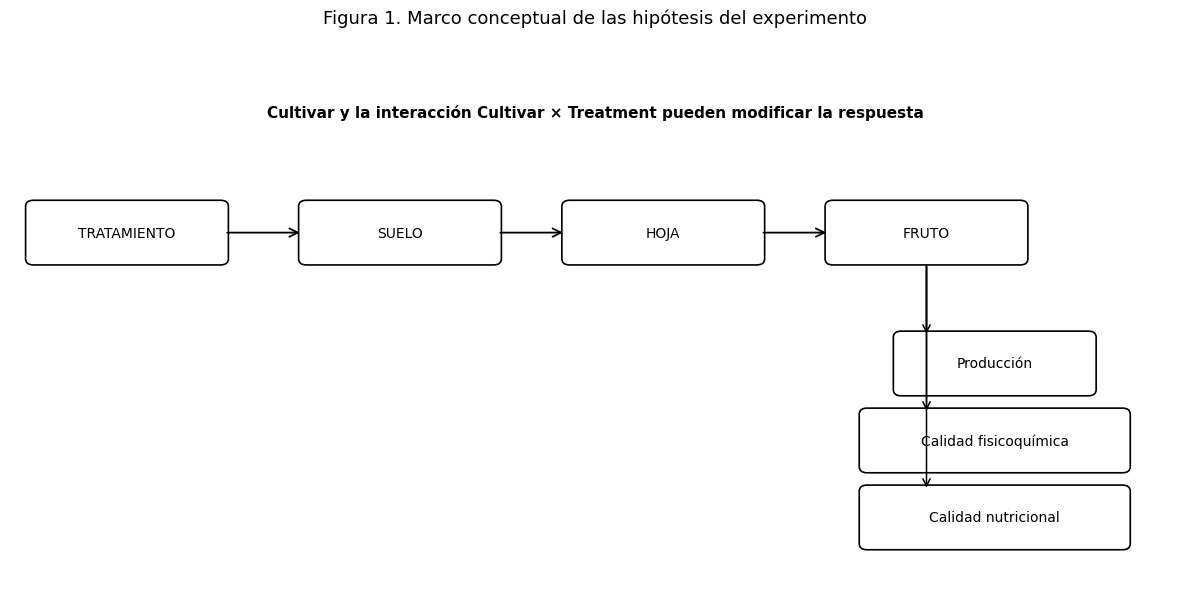

In [1]:
# Figura conceptual reproducible del marco de hipótesis.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis('off')

nodes = {
    'TRATAMIENTO': (1.2, 4.5),
    'SUELO': (4.0, 4.5),
    'HOJA': (6.7, 4.5),
    'FRUTO': (9.4, 4.5),
    'Producción': (10.1, 2.8),
    'Calidad fisicoquímica': (10.1, 1.8),
    'Calidad nutricional': (10.1, 0.8),
}
for name, (x,y) in nodes.items():
    w = 2.0 if name not in {'Calidad fisicoquímica','Calidad nutricional'} else 2.7
    box = FancyBboxPatch((x-w/2, y-0.38), w, 0.76,
                         boxstyle='round,pad=0.04,rounding_size=0.08',
                         facecolor='white', edgecolor='black', linewidth=1.2)
    ax.add_patch(box); ax.text(x, y, name, ha='center', va='center', fontsize=10)

for a,b in [('TRATAMIENTO','SUELO'),('SUELO','HOJA'),('HOJA','FRUTO')]:
    xa,ya=nodes[a]; xb,yb=nodes[b]
    ax.add_patch(FancyArrowPatch((xa+1.0,ya),(xb-1.0,yb),arrowstyle='->',mutation_scale=15,linewidth=1.3))
for child in ['Producción','Calidad fisicoquímica','Calidad nutricional']:
    xa,ya=nodes['FRUTO']; xb,yb=nodes[child]
    ax.add_patch(FancyArrowPatch((xa,ya-0.4),(xb-0.7,yb+0.35),arrowstyle='->',mutation_scale=13,linewidth=1.1))
ax.text(6.0,6.0,'Cultivar y la interacción Cultivar × Treatment pueden modificar la respuesta',
        ha='center',fontsize=11,fontweight='bold')
ax.set_title('Figura 1. Marco conceptual de las hipótesis del experimento', fontsize=13, pad=12)
plt.tight_layout(); plt.show()

# 1. Reconstrucción del experimento

### ¿Qué haremos?
Leeremos las bases de datos recolectadas y reconstruiremos una tabla analítica común.

### ¿Por qué?
Las fuentes tienen granularidades distintas. Para analizarlas conjuntamente se requiere una unidad experimental consistente y llaves de integración auditables.

### ¿Qué esperamos obtener?
Una tabla de aproximadamente **32 observaciones analíticas** (`Cultivar × Treatment × Replicate`) y **16 parcelas** (`Treatment × Replicate`), manteniendo trazabilidad hacia las fuentes originales.

In [2]:
from pathlib import Path
import re, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, skew
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', palette='deep')
SEED = 42
np.random.seed(SEED)

# Los Excel deben estar en la MISMA carpeta que la libreta.
BASE_DIR = Path.cwd().resolve()
OUT = BASE_DIR / 'outputs' / 'feature_engineering'
FIG = OUT / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
    'antiox': 'Antiox_data.xlsx',
    'sampling': 'Sampling May 2023.xlsx',
    'harvests': 'harvests.xlsx',
    'soil': 'Dataset_final_suelo.xlsx',
    'leaf': 'Dataset_final_leaf.xlsx',
    'poly_raw': 'alldata_polyphenols.xlsx',
    'anth_raw': 'Anthocyanins.xlsx',
    'vitc_raw': 'VitC_MarinaPerez.xlsx',
    'poly_table': 'Table polyphenols.xlsx',
}

missing_files = [name for name in FILES.values() if not (BASE_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        'Faltan archivos Excel en la misma carpeta del notebook: ' + ', '.join(missing_files)
    )

print('Directorio de trabajo:', BASE_DIR)
print('Archivos requeridos detectados:', len(FILES))
print('Resultados se guardarán en:', OUT)

Directorio de trabajo: /mnt/data
Archivos requeridos detectados: 9
Resultados se guardarán en: /mnt/data/outputs/feature_engineering


In [3]:
# Se conserva la misma lógica de lectura por hojas utilizada en la libreta original.
SHEETS = {
    'antiox': {'Antiox_data': None},
    'sampling': {'all_data': None},
    'harvests': {'harvests': None, 'productions_kg': None},
    'soil': {'Final': None},
    'leaf': {'Isotopes': None, 'RGB': None, 'Nitrates': None, 'Nutrients': 1},
    'poly_raw': {'alldata_polyphenols': None, 'data_polyphenols': None},
    'anth_raw': {'Cyanidin gluc': None, 'Pelargonidin gluc': None, 'Pelargonidin rutin': None},
    'vitc_raw': {'Hoja3': None},
}

inventory=[]
for key, name in FILES.items():
    book = pd.ExcelFile(BASE_DIR / name)
    for sheet in book.sheet_names:
        inventory.append({'Fuente':key,'Archivo':name,'Hoja':sheet})
    if key in SHEETS:
        for sheet in SHEETS[key]:
            if sheet not in book.sheet_names:
                raise ValueError(f'{name}: falta hoja {sheet!r}. Hojas disponibles: {book.sheet_names}')

inventory_df = pd.DataFrame(inventory)
raw={}
for key, sheets in SHEETS.items():
    for sheet, header in sheets.items():
        args={'sheet_name':sheet}
        if header is not None:
            args['header']=header
        df=pd.read_excel(BASE_DIR / FILES[key], **args)
        df.columns=[str(c).strip() for c in df.columns]
        raw[(key,sheet)] = df
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Filas']=len(df)
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Columnas']=df.shape[1]

print('Hojas revisadas:', len(inventory_df))
display(inventory_df.loc[inventory_df['Filas'].notna(), ['Fuente','Archivo','Hoja','Filas','Columnas']])

Hojas revisadas: 33


,Fuente,Archivo,Hoja,Filas,Columnas
0,antiox,Antiox_data.xlsx,Antiox_data,32.0,27.0
8,sampling,Sampling May 2023.xlsx,all_data,32.0,19.0
10,harvests,harvests.xlsx,harvests,608.0,13.0
12,harvests,harvests.xlsx,productions_kg,32.0,18.0
16,soil,Dataset_final_suelo.xlsx,Final,32.0,15.0
18,leaf,Dataset_final_leaf.xlsx,Nitrates,65.0,14.0
19,leaf,Dataset_final_leaf.xlsx,Isotopes,64.0,9.0
20,leaf,Dataset_final_leaf.xlsx,RGB,96.0,8.0
21,leaf,Dataset_final_leaf.xlsx,Nutrients,64.0,28.0
22,poly_raw,alldata_polyphenols.xlsx,alldata_polyphenols,64.0,20.0


In [4]:
antiox_raw = raw[('antiox','Antiox_data')]
fruit_raw = raw[('sampling','all_data')]
harvest_raw = raw[('harvests','harvests')]
yield_raw = raw[('harvests','productions_kg')]
soil_raw = raw[('soil','Final')]
iso_raw = raw[('leaf','Isotopes')]
rgb_raw = raw[('leaf','RGB')]
nitr_raw = raw[('leaf','Nitrates')]
nut_raw = raw[('leaf','Nutrients')].copy()
nut_raw = nut_raw.loc[:, ~nut_raw.columns.astype(str).str.startswith('Unnamed')]
nitr_raw = nitr_raw.loc[nitr_raw['Parcel/Plot'].notna()].copy()

CORE = {
    'Antioxidantes':antiox_raw, 'Calidad fruto':fruit_raw, 'Producción':yield_raw,
    'Cosechas por fecha':harvest_raw, 'Suelo':soil_raw, 'Hoja isótopos':iso_raw,
    'Hoja nitratos':nitr_raw, 'Hoja nutrientes':nut_raw, 'Hoja RGB':rgb_raw
}

def describe_source(name, df):
    return {
        'Fuente':name, 'Filas':len(df), 'Columnas':df.shape[1],
        'Numéricas':df.select_dtypes(include=np.number).shape[1],
        'NA totales':int(df.isna().sum().sum()),
        'Filas idénticas':int(df.duplicated().sum())
    }

source_profile = pd.DataFrame([describe_source(k,d) for k,d in CORE.items()])
display(source_profile)

,Fuente,Filas,Columnas,Numéricas,NA totales,Filas idénticas
0,Antioxidantes,32,27,22,12,0
1,Calidad fruto,32,19,16,14,0
2,Producción,32,18,12,99,0
3,Cosechas por fecha,608,13,8,912,0
4,Suelo,32,15,13,0,0
5,Hoja isótopos,64,9,4,0,0
6,Hoja nitratos,64,14,9,0,0
7,Hoja nutrientes,64,24,20,0,0
8,Hoja RGB,96,8,4,0,0


In [5]:
# Equivalencias de tratamientos. Se conserva el mapeo utilizado previamente.
SOIL_TO_T = {
    'COMPOST':'T1', 'N-RICH':'T2', 'NRICH':'T2',
    'RCW-HD':'T3','RWC-HD':'T3','WR-HD':'T3','RCWHD':'T3',
    'RCW-LD':'T4','RWC-LD':'T4','WR-LD':'T4','RCWLD':'T4'
}
T_TO_NAME = {'T1':'Compost', 'T2':'N-rich', 'T3':'RCW-HD / WR-HD', 'T4':'RCW-LD'}

def clean_cv(s):
    v=s.astype('string').str.strip().str.upper()
    return v.map({'DO':'Donna','DONA':'Donna','DONNA':'Donna','DR':'Dream','DREAM':'Dream'})

def clean_code(s):
    return s.astype('string').str.strip().str.upper().str.replace(r'\s+','',regex=True)

def require_cols(df, cols, label):
    missing=set(cols)-set(df.columns)
    if missing:
        raise KeyError(f'{label}: columnas no encontradas: {sorted(missing)}; disponibles={list(df.columns)}')

KEYS=['Cultivar','Treatment','Replicate']

def make_keys(df, cv, tr, rep, label):
    require_cols(df,[cv,tr,rep],label)
    return pd.DataFrame({
        'Cultivar':clean_cv(df[cv]),
        'Treatment':clean_code(df[tr]),
        'Replicate':clean_code(df[rep])
    }, index=df.index)

def check_unique(df, keys, label):
    na=df[keys].isna().any(axis=1)
    dup=df.duplicated(keys,keep=False)
    if na.any() or dup.any():
        display(df.loc[na|dup,keys].head(20))
        raise ValueError(f'{label}: claves nulas o duplicadas; no se realizará unión insegura.')

print('Tratamientos utilizados:')
display(pd.DataFrame([{'Código':k,'Tratamiento':v} for k,v in T_TO_NAME.items()]))

Tratamientos utilizados:


,Código,Tratamiento
0,T1,Compost
1,T2,N-rich
2,T3,RCW-HD / WR-HD
3,T4,RCW-LD


In [6]:
# Construcción de las fuentes principales en la unidad Cultivar × Treatment × Replicate.
ant = make_keys(antiox_raw,'cultivar','Treatment','Replicate','Antiox_data')
for c in antiox_raw.columns:
    if c not in ['Sample','cultivar','Treatment','Replicate','New_block']:
        ant[c]=pd.to_numeric(antiox_raw[c],errors='coerce')
check_unique(ant,KEYS,'Antioxidantes')

fruit = make_keys(fruit_raw,'Cv','Treatment','Repl','Sampling/all_data')
for c in ['Weight','Hydrat','Firm','Hue','Chroma','BRIX','Acidity','GA','GGA','CSI']:
    if c in fruit_raw:
        fruit['fruit_'+c]=pd.to_numeric(fruit_raw[c],errors='coerce')
check_unique(fruit,KEYS,'Calidad del fruto')

yld = make_keys(yield_raw,'Cv','Treatment','Repl','Producción')
for c in ['Com Ton/ha','No com Ton/ha','Nº de plantes','g/planta']:
    if c in yield_raw:
        yld['yield_'+c]=pd.to_numeric(yield_raw[c],errors='coerce')
check_unique(yld,KEYS,'Producción')

sets_keys={name:set(map(tuple,df[KEYS].to_numpy())) for name,df in {'Antiox':ant,'Fruto':fruit,'Producción':yld}.items()}
assert sets_keys['Antiox']==sets_keys['Fruto']==sets_keys['Producción'], 'Las claves de las fuentes principales no coinciden.'

print('Registros fuente:', {k:len(v) for k,v in {'Antiox':ant,'Fruto':fruit,'Producción':yld}.items()})

Registros fuente: {'Antiox': 32, 'Fruto': 32, 'Producción': 32}


In [7]:
# Suelo: se toma 2023 y se integra a nivel de tratamiento × réplica (parcela).
require_cols(soil_raw,['Treatment','Block','Year'],'Suelo/Final')
soil23=soil_raw.loc[pd.to_numeric(soil_raw['Year'],errors='coerce').eq(2023)].copy()
soil_t_raw=clean_code(soil23['Treatment']).str.replace('_','-',regex=False)
soil=pd.DataFrame({'Treatment':soil_t_raw.map(SOIL_TO_T), 'Replicate':clean_code(soil23['Block'])}, index=soil23.index)
for c in soil23.columns:
    if c not in ['Treatment','Year','Block','Plot']:
        soil['soil_'+c]=pd.to_numeric(soil23[c],errors='coerce')
if soil.Treatment.isna().any():
    raise ValueError('Existen tratamientos de suelo sin mapear: '+str(soil23.loc[soil.Treatment.isna(),'Treatment'].unique()))
check_unique(soil,['Treatment','Replicate'],'Suelo 2023')

def pivot_leaf(df,cv,tr,rep,time,measures,prefix,label):
    require_cols(df,[cv,tr,rep]+measures,label)
    k=make_keys(df,cv,tr,rep,label)
    k['Time']=pd.Series(time,index=df.index).astype('string').str.strip()
    for c in measures:
        k[c]=pd.to_numeric(df[c],errors='coerce')
    # Réplicas técnicas dentro de la misma unidad/fecha se resumen por media.
    piv=k.pivot_table(index=KEYS, columns='Time', values=measures, aggfunc='mean')
    piv.columns=[f'{prefix}_{str(c)}_{str(t)}' for c,t in piv.columns]
    return piv.reset_index()

iso_t=iso_raw['Date'].astype('string').str.extract('(March|May)',expand=False)
leaf_iso=pivot_leaf(iso_raw,'Cv','Treatment','Replicate',iso_t,
                    [c for c in ['%N','d13C'] if c in iso_raw], 'leaf_iso','Isotopes')

nut_vars=[c for c in nut_raw.columns if c not in ['Sample','Parcel/Plot','Cv','Treatment','Repl','Time']
          and pd.api.types.is_numeric_dtype(nut_raw[c])]
leaf_nut=pivot_leaf(nut_raw,'Cv','Treatment','Repl',nut_raw['Time'],nut_vars,'leaf_nut','Nutrients')
leaf_no3=pivot_leaf(nitr_raw,'Cv','Treatment','Repl',nitr_raw['Time'],
                    [c for c in ['mg NO3-/ g DW','mg NO3-/ 100 mg DW'] if c in nitr_raw],
                    'leaf_no3','Nitrates')
leaf_rgb=pivot_leaf(rgb_raw,'Cv','Treatment','Repl',rgb_raw['Time'],
                    [c for c in ['GA','GGA','CSI'] if c in rgb_raw], 'leaf_rgb','RGB')

print('Parcelas de suelo 2023:',len(soil))
print('Variables foliares por bloque:', {
    'Isótopos':len(leaf_iso.columns)-3,
    'Nutrientes':len(leaf_nut.columns)-3,
    'Nitratos':len(leaf_no3.columns)-3,
    'RGB':len(leaf_rgb.columns)-3
})

Parcelas de suelo 2023: 16
Variables foliares por bloque: {'Isótopos': 4, 'Nutrientes': 36, 'Nitratos': 4, 'RGB': 9}


In [8]:
# Unión principal. No depende de archivos intermedios ni de GitHub.
ana=ant.merge(fruit,on=KEYS,how='outer',validate='one_to_one',indicator='_source_fruit')
ana=ana.merge(yld,on=KEYS,how='outer',validate='one_to_one',indicator='_source_yield')
ana=ana.merge(soil,on=['Treatment','Replicate'],how='left',validate='many_to_one',indicator='_source_soil')
for x in [leaf_iso,leaf_nut,leaf_no3,leaf_rgb]:
    ana=ana.merge(x,on=KEYS,how='left',validate='one_to_one')

ana['Parcel_ID']=ana['Treatment'].astype(str)+'_'+ana['Replicate'].astype(str)
ana['Tratamiento_etiqueta']=ana['Treatment'].map(T_TO_NAME).fillna('Sin mapear')
ana['Cultivar_Treatment']=ana['Cultivar'].astype(str)+'_'+ana['Treatment'].astype(str)

assert not ana[KEYS].duplicated().any(), 'La unión generó llaves duplicadas.'
print('Filas analíticas:',len(ana))
print('Parcelas:',ana.Parcel_ID.nunique())
print('Variables numéricas:',len(ana.select_dtypes(include=np.number).columns))
print('Cruces de fuentes:')
print(ana[['_source_fruit','_source_yield','_source_soil']].value_counts(dropna=False).to_string())

if len(ana)!=32 or ana.Parcel_ID.nunique()!=16:
    warnings.warn('Cobertura distinta de 32 filas / 16 parcelas: revisar fuentes y llaves de unión.')

Filas analíticas: 32
Parcelas: 16
Variables numéricas: 100
Cruces de fuentes:
_source_fruit  _source_yield  _source_soil
both           both           both            32


In [9]:
# Interpretación automática del resultado de integración.
msg = (
    f'**Resultado.** Se reconstruyeron **{len(ana)} observaciones analíticas** y '
    f'**{ana.Parcel_ID.nunique()} parcelas**. La unidad principal es `Cultivar × Treatment × Replicate`, '
    'mientras que `Parcel_ID = Treatment × Replicate` conserva la dependencia compartida del suelo. '
    'Esta estructura se utilizará posteriormente para evitar fuga de información entre entrenamiento y prueba.'
)
display(Markdown(msg))

**Resultado.** Se reconstruyeron **32 observaciones analíticas** y **16 parcelas**. La unidad principal es `Cultivar × Treatment × Replicate`, mientras que `Parcel_ID = Treatment × Replicate` conserva la dependencia compartida del suelo. Esta estructura se utilizará posteriormente para evitar fuga de información entre entrenamiento y prueba.

# 2. Separación entre diseño, predictores y resultados

### ¿Qué haremos?
Organizaremos las columnas en bloques científicos: diseño experimental, suelo, hoja/nutrición, RGB/fisiología, producción, calidad fisicoquímica y calidad nutricional.

### ¿Por qué?
No todas las variables cumplen el mismo papel. Mezclar resultados del fruto con condiciones de suelo/hoja como si fueran predictores equivalentes puede generar interpretaciones circulares.

### ¿Qué esperamos obtener?
Una arquitectura explícita de `X` y familias de resultados `Y`, evitando utilizar `yield_g/planta` como único objetivo del estudio.

In [10]:
# Los bloques se detectan a partir de los nombres creados durante la integración, no desde una lista rígida externa.
design_cols=['Cultivar','Treatment','Replicate','Parcel_ID','Tratamiento_etiqueta','Cultivar_Treatment']
soil_cols=[c for c in ana if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana[c])]
leaf_nutrition_cols=[c for c in ana if c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) and pd.api.types.is_numeric_dtype(ana[c])]
rgb_cols=[c for c in ana if c.startswith('leaf_rgb_') and pd.api.types.is_numeric_dtype(ana[c])]
production_cols=[c for c in ana if c.startswith('yield_') and pd.api.types.is_numeric_dtype(ana[c])]
physchem_cols=[c for c in ana if c.startswith('fruit_') and pd.api.types.is_numeric_dtype(ana[c])]
# Las columnas de ant se capturan directamente de la fuente consolidada de antioxidantes.
nutritional_cols=[c for c in ant.columns if c not in KEYS and c in ana.columns and pd.api.types.is_numeric_dtype(ana[c])]

BLOCKS={
    'Diseño experimental':design_cols,
    'Suelo':soil_cols,
    'Hoja / nutrición':leaf_nutrition_cols,
    'Hoja / RGB-fisiología':rgb_cols,
    'Producción':production_cols,
    'Calidad fisicoquímica':physchem_cols,
    'Calidad nutricional':nutritional_cols,
}
block_summary=pd.DataFrame([{'Bloque':k,'Variables':len(v)} for k,v in BLOCKS.items()])
display(block_summary)

X_raw_cols=soil_cols+leaf_nutrition_cols+rgb_cols
outcome_families={
    'Producción':production_cols,
    'Fisicoquímica':physchem_cols,
    'Nutricional':nutritional_cols,
}
print('Predictores X crudos:',len(X_raw_cols))
print('Resultados Y disponibles:',sum(len(v) for v in outcome_families.values()))

,Bloque,Variables
0,Diseño experimental,6
1,Suelo,11
2,Hoja / nutrición,44
3,Hoja / RGB-fisiología,9
4,Producción,4
5,Calidad fisicoquímica,10
6,Calidad nutricional,22


Predictores X crudos: 64
Resultados Y disponibles: 36


# 3. Auditoría de calidad y valores atípicos

### ¿Qué haremos?
Revisaremos valores faltantes y detectaremos atípicos con IQR, registrándolos junto con cultivar, tratamiento y parcela.

### ¿Por qué?
En este estudio un extremo puede ser un error, pero también una combinación experimental excepcional. Por ello, un boxplot no es suficiente para justificar una eliminación.

### ¿Qué esperamos obtener?
Un registro de casos a investigar (`outlier_registry`) y una política explícita: **detectar y contextualizar antes de excluir**.

In [11]:
# 3.1 Valores faltantes: todavía NO se imputa.
missing=pd.DataFrame({
    'faltantes':ana.isna().sum(),
    'porcentaje':100*ana.isna().mean()
}).query('faltantes > 0').sort_values(['faltantes','porcentaje'],ascending=False)
print('Celdas faltantes totales:',int(ana.isna().sum().sum()))
display(missing)

Celdas faltantes totales: 14


,faltantes,porcentaje
P gluc,3,9.375
P rut,3,9.375
Cyan,3,9.375
Tot anth,3,9.375
fruit_Hue,1,3.125
fruit_Chroma,1,3.125


In [12]:
# 3.2 Registro de atípicos por IQR. Se usa como detector, no como regla de eliminación.
def detectar_atipicos_iqr(df, columnas):
    registros=[]
    for col in columnas:
        x=pd.to_numeric(df[col],errors='coerce')
        q1=x.quantile(0.25); q3=x.quantile(0.75); iqr=q3-q1
        if not np.isfinite(iqr) or iqr<=0:
            continue
        lo=q1-1.5*iqr; hi=q3+1.5*iqr
        mask=(x<lo)|(x>hi)
        for idx in df.index[mask]:
            val=float(x.loc[idx])
            severity=(lo-val)/iqr if val<lo else (val-hi)/iqr
            registros.append({
                'indice':idx,'variable':col,'valor':val,
                'Cultivar':df.loc[idx,'Cultivar'],'Treatment':df.loc[idx,'Treatment'],
                'Replicate':df.loc[idx,'Replicate'],'Parcel_ID':df.loc[idx,'Parcel_ID'],
                'limite_inferior':float(lo),'limite_superior':float(hi),
                'direccion':'bajo' if val<lo else 'alto','severidad_iqr':float(severity)
            })
    return pd.DataFrame(registros)

numeric_audit=[c for c in ana.select_dtypes(include=np.number).columns]
outlier_registry=detectar_atipicos_iqr(ana,numeric_audit)
print('Casos atípicos detectados (variable-observación):',len(outlier_registry))
if not outlier_registry.empty:
    display(outlier_registry.sort_values('severidad_iqr',ascending=False).head(25))
else:
    print('No se detectaron valores atípicos con la regla IQR configurada.')

Casos atípicos detectados (variable-observación): 133


,indice,variable,valor,Cultivar,Treatment,Replicate,Parcel_ID,limite_inferior,limite_superior,direccion,severidad_iqr
103,0,leaf_nut_Pb_March,31.058969,Donna,T1,R1,T1_R1,0.747499,1.949458,alto,96.873555
91,23,leaf_nut_Mo_May,13.946345,Dream,T2,R4,T2_R4,-0.240582,0.536469,alto,69.029607
72,15,leaf_nut_Cd_March,1.286800,Donna,T4,R4,T4_R4,-0.036782,0.080166,alto,41.270956
74,2,leaf_nut_Cd_May,0.617643,Donna,T1,R3,T1_R3,-0.031443,0.053204,alto,26.672611
107,16,leaf_nut_Pb_March,9.394810,Dream,T1,R1,T1_R1,0.747499,1.949458,alto,24.777391
73,16,leaf_nut_Cd_March,0.655945,Dream,T1,R1,T1_R1,-0.036782,0.080166,alto,19.693572
90,20,leaf_nut_Mo_May,3.911133,Dream,T2,R1,T2_R1,-0.240582,0.536469,alto,17.371654
93,31,leaf_nut_Mo_May,3.608754,Dream,T4,R4,T4_R4,-0.240582,0.536469,alto,15.815111
79,16,leaf_nut_Cd_May,0.338934,Dream,T1,R1,T1_R1,-0.031443,0.053204,alto,13.502214
83,29,leaf_nut_Cr_May,12.739001,Dream,T4,R2,T4_R2,-1.000597,2.171653,alto,13.324736


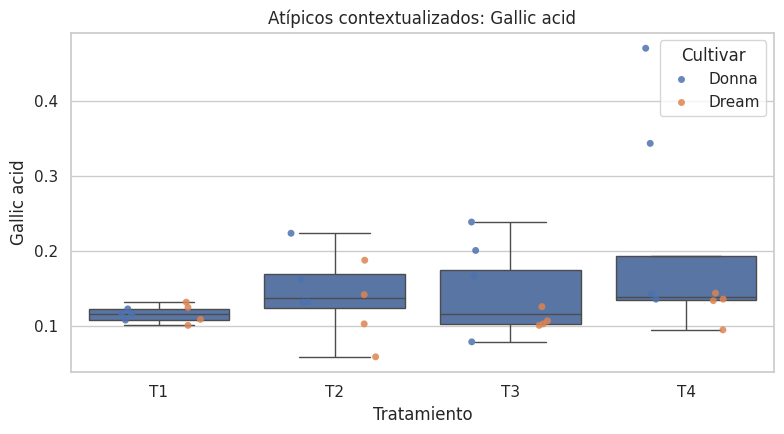

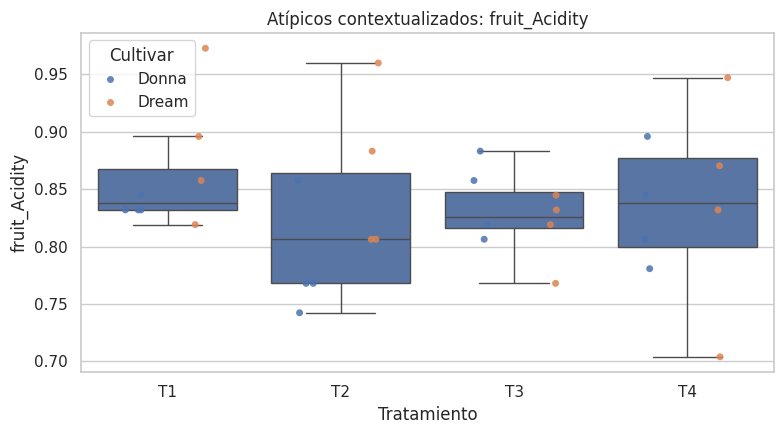

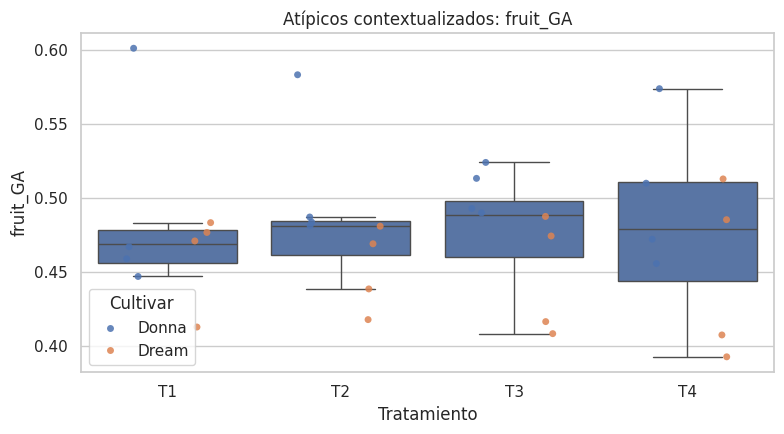

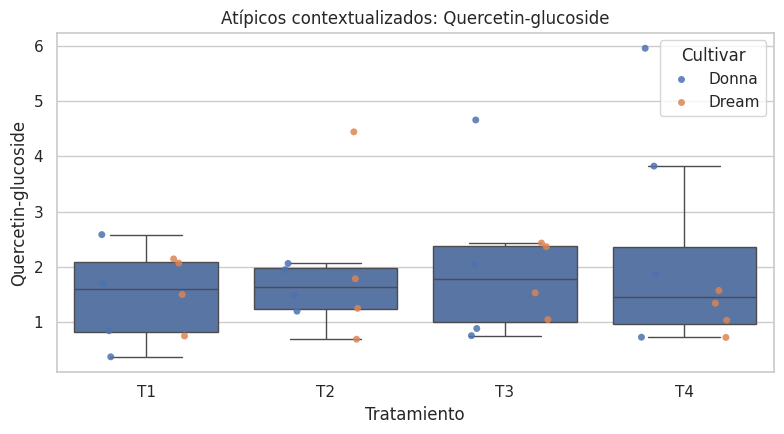

,variable,valor,direccion,severidad_iqr,Cultivar,Treatment,Replicate,Parcel_ID
103,leaf_nut_Pb_March,31.058969,alto,96.873555,Donna,T1,R1,T1_R1
91,leaf_nut_Mo_May,13.946345,alto,69.029607,Dream,T2,R4,T2_R4
72,leaf_nut_Cd_March,1.286800,alto,41.270956,Donna,T4,R4,T4_R4
74,leaf_nut_Cd_May,0.617643,alto,26.672611,Donna,T1,R3,T1_R3
107,leaf_nut_Pb_March,9.394810,alto,24.777391,Dream,T1,R1,T1_R1
73,leaf_nut_Cd_March,0.655945,alto,19.693572,Dream,T1,R1,T1_R1
90,leaf_nut_Mo_May,3.911133,alto,17.371654,Dream,T2,R1,T2_R1
93,leaf_nut_Mo_May,3.608754,alto,15.815111,Dream,T4,R4,T4_R4
79,leaf_nut_Cd_May,0.338934,alto,13.502214,Dream,T1,R1,T1_R1
83,leaf_nut_Cr_May,12.739001,alto,13.324736,Dream,T4,R2,T4_R2


In [13]:
# 3.3 Contextualización visual: priorizamos variables de RESULTADO que presenten atípicos.
outcome_cols_all=list(dict.fromkeys(production_cols+physchem_cols+nutritional_cols))
if not outlier_registry.empty:
    out_counts=(outlier_registry[outlier_registry['variable'].isin(outcome_cols_all)]
                .groupby('variable').size().sort_values(ascending=False))
    vars_plot=list(out_counts.head(4).index)
    if not vars_plot:
        vars_plot=list(outlier_registry.groupby('variable').size().sort_values(ascending=False).head(4).index)
    for col in vars_plot:
        fig,ax=plt.subplots(figsize=(8,4.5))
        sns.boxplot(data=ana,x='Treatment',y=col,ax=ax,showfliers=False)
        sns.stripplot(data=ana,x='Treatment',y=col,hue='Cultivar',dodge=True,ax=ax,alpha=.85)
        ax.set_title(f'Atípicos contextualizados: {col}')
        ax.set_xlabel('Tratamiento'); ax.set_ylabel(col)
        plt.tight_layout(); plt.show()

# Resumen de los casos más extremos con contexto experimental.
if not outlier_registry.empty:
    top_ctx=outlier_registry.sort_values('severidad_iqr',ascending=False).head(12).copy()
    display(top_ctx[['variable','valor','direccion','severidad_iqr','Cultivar','Treatment','Replicate','Parcel_ID']])

In [14]:
# Interpretación, sin eliminar observaciones.
if outlier_registry.empty:
    txt='**Interpretación.** No se detectaron extremos mediante IQR. Por tanto, no existe motivo para excluir observaciones por este criterio.'
else:
    nvars=outlier_registry['variable'].nunique()
    high=int((outlier_registry['direccion']=='alto').sum())
    txt=(f'**Interpretación.** El criterio IQR marcó **{len(outlier_registry)} casos** distribuidos en **{nvars} variables**; '
         f'**{high}** corresponden a extremos altos. Estos registros se conservan porque pueden representar respuestas biológicas reales o combinaciones favorables. '
         'La eliminación queda reservada para errores confirmados de captura, medición o integración.')
display(Markdown(txt))

**Interpretación.** El criterio IQR marcó **133 casos** distribuidos en **51 variables**; **114** corresponden a extremos altos. Estos registros se conservan porque pueden representar respuestas biológicas reales o combinaciones favorables. La eliminación queda reservada para errores confirmados de captura, medición o integración.

# 4. Política de limpieza y preprocesamiento

### ¿Qué haremos?
Documentaremos los criterios antes de ejecutar transformaciones.

### ¿Por qué?
Una política previa reduce decisiones ad hoc y permite distinguir entre limpieza técnica, transformación estadística y selección de características.

### ¿Qué esperamos obtener?
Trazabilidad completa de las reglas utilizadas durante la preparación de datos.

| Situación | Criterio | Acción |
|---|---|---|
| Valores faltantes en X | Pocos y sin patrón estructural | Imputación por mediana ajustada únicamente con train |
| Variable totalmente vacía | Sin información | Eliminar y documentar |
| Atípico biológicamente plausible | Posible respuesta experimental real | Conservar |
| Atípico con error confirmado | Error de captura/medición/integración | Corregir o excluir documentando la causa |
| Asimetría | `|skew| > 1` | Yeo-Johnson |
| Categórica sin orden | Variable nominal | One-Hot Encoding |
| Escalas diferentes | Unidades heterogéneas | StandardScaler |
| Varianza nula | Sin información | Eliminar |
| Duplicado exacto | Redundancia completa | Conservar una variable |
| Alta correlación | `|Spearman| ≥ 0.95` | Conservar un representante |
| Mediciones temporales | Dos o más fechas comparables | Crear baseline + delta |
| Parcela compartida | Riesgo de leakage | Split agrupado por `Parcel_ID` |

# 5. Ingeniería de características

### ¿Qué haremos?
Representaremos la evolución temporal mediante **baseline + delta**, crearemos una etiqueta descriptiva `Cultivar_Treatment` y mantendremos una discretización únicamente demostrativa.

### ¿Por qué?
El cambio temporal puede ser más interpretable que conservar dos mediciones altamente redundantes. Al mismo tiempo, evitamos crear ratios o interacciones numéricas sin fundamento científico.

### ¿Qué esperamos obtener?
Una matriz de características más informativa y compacta, sin aumentar innecesariamente la dimensionalidad.

In [15]:
def feature_builder(df):
    z=df.copy()
    created={}
    removed=[]
    original=list(z.columns)

    # Dos momentos (March, May): conservar March como baseline y reemplazar May por delta May-March.
    for family in ['leaf_iso_','leaf_no3_','leaf_nut_']:
        may_cols=[c for c in original if c.startswith(family) and c.endswith('_May')]
        for may in may_cols:
            march=may[:-3]+'March'
            if march in z.columns:
                new='FE_delta_'+may.replace('_May','')
                z[new]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[march],errors='coerce')
                created[new]=f'Cambio May - March; baseline conservado en {march}.'
                removed.append(may)

    # RGB tiene December, March y May: baseline December + dos cambios secuenciales.
    rgb_metrics=sorted({c.rsplit('_',1)[0] for c in original if c.startswith('leaf_rgb_')})
    for base in rgb_metrics:
        dec,mar,may=base+'_December',base+'_March',base+'_May'
        if dec in z and mar in z:
            d1='FE_delta_'+base+'_March_minus_December'
            z[d1]=pd.to_numeric(z[mar],errors='coerce')-pd.to_numeric(z[dec],errors='coerce')
            created[d1]=f'Cambio March - December para {base}; December funciona como baseline.'
            removed.append(mar)
        if mar in z and may in z:
            d2='FE_delta_'+base+'_May_minus_March'
            z[d2]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[mar],errors='coerce')
            created[d2]=f'Cambio May - March para {base}.'
            removed.append(may)

    # Eliminar solo puntos finales que quedan matemáticamente representados por baseline + delta.
    removed=list(dict.fromkeys([c for c in removed if c in z.columns]))
    z=z.drop(columns=removed)
    return z,created,removed

ana_fe, derived, temporal_removed = feature_builder(ana)
ana_fe['Cultivar_Treatment']=ana_fe['Cultivar'].astype(str)+'_'+ana_fe['Treatment'].astype(str)

print('Características temporales creadas:',len(derived))
print('Mediciones finales redundantes retiradas:',len(temporal_removed))
display(pd.DataFrame([{'Variable':k,'Justificación':v} for k,v in derived.items()]).head(30))

Características temporales creadas: 28
Mediciones finales redundantes retiradas: 28


,Variable,Justificación
0,FE_delta_leaf_iso_%N,Cambio May - March; baseline conservado en lea...
1,FE_delta_leaf_iso_d13C,Cambio May - March; baseline conservado en lea...
2,FE_delta_leaf_no3_mg NO3-/ 100 mg DW,Cambio May - March; baseline conservado en lea...
3,FE_delta_leaf_no3_mg NO3-/ g DW,Cambio May - March; baseline conservado en lea...
4,FE_delta_leaf_nut_B,Cambio May - March; baseline conservado en lea...
5,FE_delta_leaf_nut_Ca,Cambio May - March; baseline conservado en lea...
6,FE_delta_leaf_nut_Cd,Cambio May - March; baseline conservado en lea...
7,FE_delta_leaf_nut_Co,Cambio May - March; baseline conservado en lea...
8,FE_delta_leaf_nut_Cr,Cambio May - March; baseline conservado en lea...
9,FE_delta_leaf_nut_Cu,Cambio May - March; baseline conservado en lea...


In [16]:
# 5.4 Binning únicamente demostrativo: no será predictor.
# Se selecciona una variable de producción continua disponible para mostrar la técnica.
bin_target=next((c for c in production_cols if c in ana_fe and ana_fe[c].notna().sum()>=12 and ana_fe[c].nunique()>=3),None)
if bin_target is not None:
    qs=np.unique(ana_fe[bin_target].dropna().quantile([1/3,2/3]).to_numpy())
    if len(qs)==2:
        bins=[-np.inf,*qs,np.inf]
        demo=ana_fe[['Cultivar','Treatment',bin_target]].copy()
        demo['nivel_descriptivo']=pd.cut(demo[bin_target],bins=bins,labels=['Bajo','Medio','Alto'],include_lowest=True)
        print('Binning demostrativo sobre:',bin_target,'| umbrales:',qs)
        display(demo.groupby(['Treatment','nivel_descriptivo'],observed=True).size().rename('n').reset_index())
        display(Markdown('**Nota.** La discretización se muestra para documentar la técnica, pero no se utilizará como predictor porque perdería información continua y no existen umbrales científicos establecidos.'))
else:
    print('No se encontró una variable adecuada para demostrar binning.')

Binning demostrativo sobre: yield_Com Ton/ha | umbrales: [3.17925926 7.38014815]


,Treatment,nivel_descriptivo,n
0,T1,Bajo,2
1,T1,Medio,3
2,T1,Alto,3
3,T2,Bajo,4
4,T2,Medio,1
5,T2,Alto,3
6,T3,Bajo,3
7,T3,Medio,3
8,T3,Alto,2
9,T4,Bajo,2


**Nota.** La discretización se muestra para documentar la técnica, pero no se utilizará como predictor porque perdería información continua y no existen umbrales científicos establecidos.

In [17]:
# Reconstrucción de bloques después de la ingeniería temporal.
soil_fe=[c for c in ana_fe if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana_fe[c])]
leaf_fe=[c for c in ana_fe if (c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) or c.startswith(('FE_delta_leaf_nut_','FE_delta_leaf_iso_','FE_delta_leaf_no3_'))) and pd.api.types.is_numeric_dtype(ana_fe[c])]
rgb_fe=[c for c in ana_fe if (c.startswith('leaf_rgb_') or c.startswith('FE_delta_leaf_rgb_')) and pd.api.types.is_numeric_dtype(ana_fe[c])]
X_fe_cols=list(dict.fromkeys(soil_fe+leaf_fe+rgb_fe))

work_cols=list(dict.fromkeys(['Cultivar','Treatment','Replicate','Parcel_ID','Tratamiento_etiqueta','Cultivar_Treatment'] + X_fe_cols + production_cols + physchem_cols + nutritional_cols))
work=ana_fe[work_cols].copy().replace([np.inf,-np.inf],np.nan)

summary_fe=pd.DataFrame([
    {'Etapa':'Predictores crudos','Variables':len(X_raw_cols)},
    {'Etapa':'Predictores después de FE temporal','Variables':len(X_fe_cols)},
    {'Etapa':'Features nuevas','Variables':len(derived)},
    {'Etapa':'Mediciones finales redundantes retiradas','Variables':len(temporal_removed)},
])
display(summary_fe)

,Etapa,Variables
0,Predictores crudos,64
1,Predictores después de FE temporal,64
2,Features nuevas,28
3,Mediciones finales redundantes retiradas,28


# 6. División Train/Test evitando leakage

### ¿Qué haremos?
Separaremos entrenamiento y prueba mediante `GroupShuffleSplit`, agrupando por `Parcel_ID`.

### ¿Por qué?
Dos cultivares asociados a la misma parcela comparten información de suelo. Si una observación de esa parcela estuviera en train y otra en test, el modelo podría beneficiarse de información casi duplicada.

### ¿Qué esperamos obtener?
Conjuntos independientes a nivel de parcela, manteniendo la estructura experimental.

In [18]:
from sklearn.model_selection import GroupShuffleSplit

split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED)
itr,ite=next(split.split(work, groups=work['Parcel_ID']))
tr=work.iloc[itr].copy(); te=work.iloc[ite].copy()

assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
print('Entrenamiento:',tr.shape,'| Prueba:',te.shape)
print('Parcelas train/test:',tr.Parcel_ID.nunique(),te.Parcel_ID.nunique())
print('Overlap de parcelas:',set(tr.Parcel_ID)&set(te.Parcel_ID))
print('Parcelas train:',sorted(tr.Parcel_ID.unique()))
print('Parcelas test:',sorted(te.Parcel_ID.unique()))

Entrenamiento: (24, 106) | Prueba: (8, 106)
Parcelas train/test: 12 4
Overlap de parcelas: set()
Parcelas train: ['T1_R3', 'T1_R4', 'T2_R1', 'T2_R3', 'T2_R4', 'T3_R1', 'T3_R2', 'T3_R3', 'T3_R4', 'T4_R1', 'T4_R2', 'T4_R4']
Parcelas test: ['T1_R1', 'T1_R2', 'T2_R2', 'T4_R3']


# 7. Transformación y escalamiento

### ¿Qué haremos?
Imputaremos faltantes de `X` por mediana, aplicaremos Yeo-Johnson cuando `|skew| > 1`, estandarizaremos numéricas y codificaremos `Cultivar` y `Treatment` con One-Hot Encoding.

### ¿Por qué?
Las variables provienen de escalas muy distintas y algunas presentan distribuciones fuertemente asimétricas. PCA, clustering y otros algoritmos sensibles a distancias requieren una representación comparable.

### ¿Qué esperamos obtener?
Matrices de entrenamiento y prueba consistentes, sin faltantes y sin ajustar transformadores con información del conjunto de prueba.

In [19]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder

numeric_candidates=[c for c in X_fe_cols if c in tr.columns and pd.api.types.is_numeric_dtype(tr[c])]
all_missing=[c for c in numeric_candidates if tr[c].notna().sum()==0]
num_cols=[c for c in numeric_candidates if c not in all_missing]
assert num_cols, 'Sin predictores numéricos disponibles.'

imputer=SimpleImputer(strategy='median')
Xtr0=pd.DataFrame(imputer.fit_transform(tr[num_cols]),columns=num_cols,index=tr.index)
Xte0=pd.DataFrame(imputer.transform(te[num_cols]),columns=num_cols,index=te.index)

sk0=Xtr0.apply(lambda x: skew(x.to_numpy(),bias=False) if x.nunique()>2 else 0).replace([np.inf,-np.inf],0).fillna(0)
transformed=[c for c in num_cols if abs(sk0[c])>1 and Xtr0[c].nunique()>3]
Xtr1=Xtr0.copy(); Xte1=Xte0.copy(); transformers={}; diagnostics=[]
for c in transformed:
    pt=PowerTransformer(method='yeo-johnson',standardize=False)
    try:
        Xtr1[c]=pt.fit_transform(Xtr0[[c]]).ravel()
        Xte1[c]=pt.transform(Xte0[[c]]).ravel()
        transformers[c]=pt
        diagnostics.append({'variable':c,'skew_antes':float(sk0[c]),'skew_despues':float(skew(Xtr1[c],bias=False))})
    except (ValueError,FloatingPointError) as e:
        Xtr1[c]=Xtr0[c]; Xte1[c]=Xte0[c]
        print('Yeo-Johnson omitida:',c,str(e))

scaler=StandardScaler()
Xtr_num=pd.DataFrame(scaler.fit_transform(Xtr1),index=tr.index,columns=num_cols)
Xte_num=pd.DataFrame(scaler.transform(Xte1),index=te.index,columns=num_cols)

try:
    ohe=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:
    ohe=OneHotEncoder(handle_unknown='ignore',sparse=False)
cat_cols=['Cultivar','Treatment']
Xtr_cat=pd.DataFrame(ohe.fit_transform(tr[cat_cols]),index=tr.index,columns=ohe.get_feature_names_out(cat_cols))
Xte_cat=pd.DataFrame(ohe.transform(te[cat_cols]),index=te.index,columns=ohe.get_feature_names_out(cat_cols))

transform_report=pd.DataFrame(diagnostics,columns=['variable','skew_antes','skew_despues'])
print('Candidatas X:',len(numeric_candidates),'| Totalmente ausentes en train:',len(all_missing),'| Yeo-Johnson:',len(transformers),'| OHE:',Xtr_cat.shape[1])
display(transform_report.sort_values('skew_antes',key=lambda s:s.abs(),ascending=False).head(20) if not transform_report.empty else pd.DataFrame({'mensaje':['Sin Yeo-Johnson necesaria']}))

Candidatas X: 64 | Totalmente ausentes en train: 0 | Yeo-Johnson: 11 | OHE: 6


,variable,skew_antes,skew_despues
0,leaf_nut_Cd_March,4.875843,1.826643
9,FE_delta_leaf_nut_Cr,4.117805,-0.100881
10,FE_delta_leaf_nut_Mo,3.953442,0.162890
1,leaf_nut_Cu_March,3.577323,0.076874
8,FE_delta_leaf_nut_Cd,-3.110344,0.623831
5,leaf_nut_Si_March,2.148076,0.156071
3,leaf_nut_Ni_March,1.981521,0.047815
4,leaf_nut_Pb_March,1.901072,-0.004707
6,FE_delta_leaf_no3_mg NO3-/ 100 mg DW,1.481774,-0.037598
7,FE_delta_leaf_no3_mg NO3-/ g DW,1.474931,0.087790


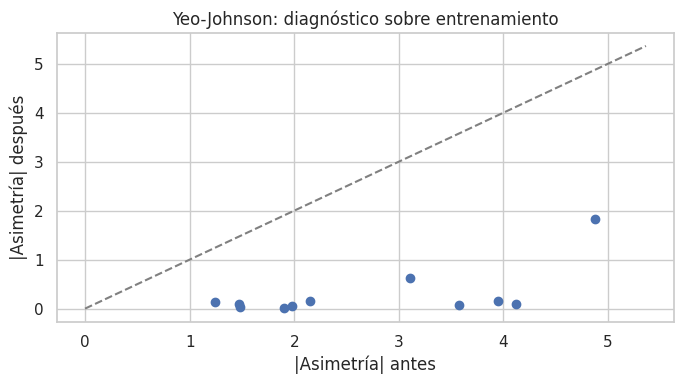

,variable,skew_antes,skew_despues,mejora_abs_asimetria
9,FE_delta_leaf_nut_Cr,4.117805,-0.100881,4.016924
10,FE_delta_leaf_nut_Mo,3.953442,0.162890,3.790552
1,leaf_nut_Cu_March,3.577323,0.076874,3.500449


**Interpretación.** Se aplicó Yeo-Johnson a **11 variables** con asimetría elevada. El gráfico compara la magnitud antes y después; los puntos por debajo de la diagonal representan reducción de asimetría. Los parámetros se ajustaron únicamente con train.

In [20]:
# Diagnóstico antes/después de Yeo-Johnson.
if not transform_report.empty:
    transform_report['mejora_abs_asimetria']=transform_report.skew_antes.abs()-transform_report.skew_despues.abs()
    fig,ax=plt.subplots(figsize=(7,4))
    ax.scatter(transform_report.skew_antes.abs(),transform_report.skew_despues.abs())
    limit=max(1.,float(transform_report[['skew_antes','skew_despues']].abs().max().max())*1.1)
    ax.plot([0,limit],[0,limit],linestyle='--',color='gray')
    ax.set(xlabel='|Asimetría| antes',ylabel='|Asimetría| después',title='Yeo-Johnson: diagnóstico sobre entrenamiento')
    plt.tight_layout(); plt.show()
    best=transform_report.sort_values('mejora_abs_asimetria',ascending=False).head(3)
    display(best)
    display(Markdown(f'**Interpretación.** Se aplicó Yeo-Johnson a **{len(transform_report)} variables** con asimetría elevada. El gráfico compara la magnitud antes y después; los puntos por debajo de la diagonal representan reducción de asimetría. Los parámetros se ajustaron únicamente con train.'))
else:
    display(Markdown('**Interpretación.** Ninguna variable cumplió simultáneamente los criterios de asimetría y variabilidad requeridos para Yeo-Johnson.'))

# 8. Selección de características no supervisada

### ¿Qué haremos?
Aplicaremos filtros de varianza nula, duplicación exacta y correlación Spearman extrema (`|ρ| ≥ 0.95`).

### ¿Por qué?
El conjunto tiene muchas variables respecto al número de observaciones. Reducir redundancia ayuda a limitar complejidad sin depender todavía de una variable objetivo.

### ¿Qué esperamos obtener?
Una matriz `X_filtered` más compacta y una bitácora que documente qué característica fue retirada y por qué.

In [21]:
filter_log=[]
var=Xtr_num.var(ddof=0)
keep=[c for c in num_cols if var[c]>1e-12]
for c in num_cols:
    if c not in keep:
        filter_log.append({'Feature':c,'Etapa':'Variance threshold','Razón':'Varianza nula en entrenamiento'})

nondup=[]
for c in keep:
    copied=next((d for d in nondup if np.allclose(Xtr_num[c].to_numpy(),Xtr_num[d].to_numpy(),atol=1e-10,rtol=1e-10)),None)
    if copied:
        filter_log.append({'Feature':c,'Etapa':'Duplicate','Razón':'Duplicado exacto de '+copied})
    else:
        nondup.append(c)

# Se priorizan variables originales/baseline frente a derivadas cuando existe redundancia extrema.
def priority_feature(name):
    return (name.startswith('FE_'), name)

selected_corr=[]
high_corr=[]
for c in sorted(nondup,key=priority_feature):
    conflict=None
    for d in selected_corr:
        rho=spearmanr(Xtr_num[c],Xtr_num[d]).statistic
        if np.isfinite(rho) and abs(rho)>=0.95:
            conflict=(d,rho); break
    if conflict:
        filter_log.append({'Feature':c,'Etapa':'Correlation','Razón':f'Spearman {conflict[1]:.3f} con {conflict[0]}'})
        high_corr.append({'Variable_1':d,'Variable_2':c,'Spearman':conflict[1]})
    else:
        selected_corr.append(c)

assert selected_corr,'Ninguna variable sobrevivió al filtrado.'
Xtr_depurado=pd.concat([Xtr_num[selected_corr],Xtr_cat],axis=1)
Xte_depurado=pd.concat([Xte_num[selected_corr],Xte_cat],axis=1)

print('Iniciales:',len(num_cols),'| varianza:',len(keep),'| no duplicadas:',len(nondup),'| no redundantes:',len(selected_corr))
display(pd.DataFrame(high_corr).sort_values('Spearman',key=lambda s:s.abs(),ascending=False).head(20) if high_corr else pd.DataFrame({'mensaje':['Sin pares >= 0.95']}))

Iniciales: 64 | varianza: 64 | no duplicadas: 64 | no redundantes: 60


,Variable_1,Variable_2,Spearman
1,soil_Microbial_biomass_C_incubado,soil_N_microbiano_incubado,0.985940
0,leaf_no3_mg NO3-/ 100 mg DW_March,leaf_no3_mg NO3-/ g DW_March,0.970435
2,FE_delta_leaf_no3_mg NO3-/ 100 mg DW,FE_delta_leaf_no3_mg NO3-/ g DW,0.957391
3,FE_delta_leaf_nut_Co,FE_delta_leaf_nut_Fe,0.955652


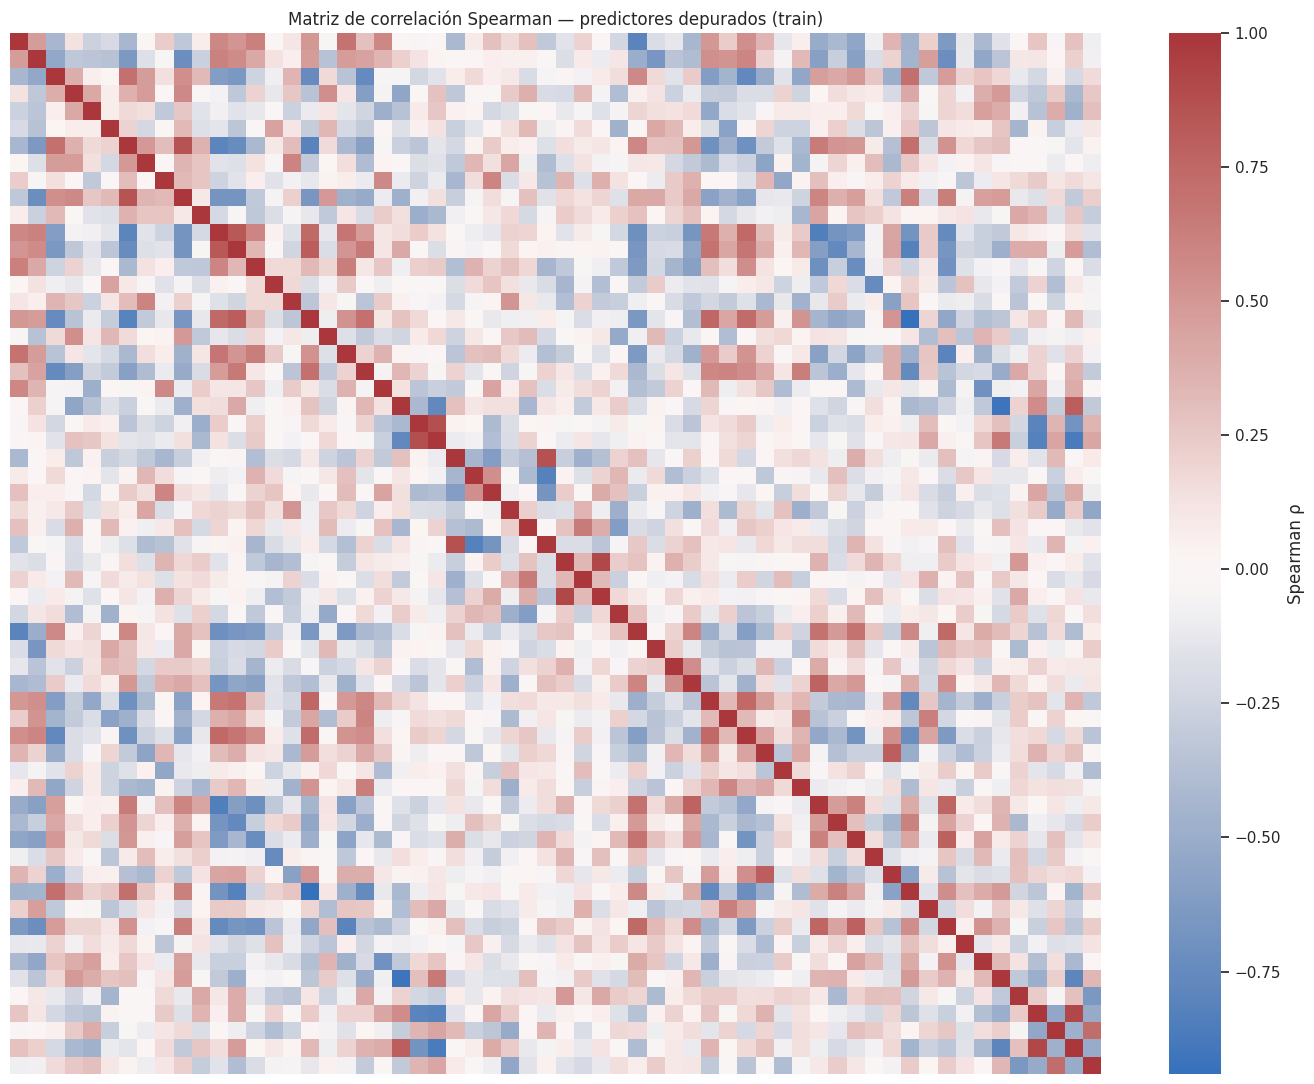

**Interpretación.** De **64** características numéricas preprocesadas, **60** sobreviven a los filtros no supervisados. Se retiraron **4** por falta de variación, duplicación o redundancia extrema. La correlación se usa para reducir información repetida, no para descartar variables por su asociación con un resultado.

In [22]:
# Matriz de correlación completa sobre las variables depuradas; se muestra por bloques para mantener legibilidad.
corr=Xtr_num[selected_corr].corr(method='spearman')
fig,ax=plt.subplots(figsize=(14,11))
sns.heatmap(corr,ax=ax,cmap='vlag',center=0,xticklabels=False,yticklabels=False,cbar_kws={'label':'Spearman ρ'})
ax.set_title('Matriz de correlación Spearman — predictores depurados (train)')
plt.tight_layout(); plt.show()

display(Markdown(
    f'**Interpretación.** De **{len(num_cols)}** características numéricas preprocesadas, **{len(selected_corr)}** sobreviven a los filtros no supervisados. '
    f'Se retiraron **{len(num_cols)-len(selected_corr)}** por falta de variación, duplicación o redundancia extrema. '
    'La correlación se usa para reducir información repetida, no para descartar variables por su asociación con un resultado.'
))

# 9. Relevancia de características por familias de resultados

### ¿Qué haremos?
Evaluaremos la relevancia exploratoria de los predictores frente a tres familias de resultados: **producción**, **calidad fisicoquímica** y **calidad nutricional**.

### ¿Por qué?
El rendimiento no es el único resultado científico. Una característica poco informativa para producción puede ser importante para vitamina C, polifenoles o calidad fisicoquímica.

### ¿Qué esperamos obtener?
Rankings comparables mediante F-regression, Mutual Information y, cuando el tamaño del conjunto de prueba lo permita, Permutation Importance con un modelo simple. Los resultados se interpretan como **asociaciones predictivas exploratorias, no causalidad**.

In [23]:
from sklearn.feature_selection import f_regression, mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

Xtr_model=pd.concat([Xtr_num[selected_corr],Xtr_cat],axis=1)
Xte_model=pd.concat([Xte_num[selected_corr],Xte_cat],axis=1)

# Normaliza un vector de scores a percentiles 0-100 (100 = mejor posición relativa).
def percentile_score(series):
    s=pd.Series(series,dtype=float).replace([np.inf,-np.inf],np.nan).fillna(0)
    if len(s)<=1:
        return pd.Series(np.ones(len(s))*100,index=s.index)
    return s.rank(pct=True,method='average')*100

relevance_rows=[]
family_tables={}

for family, outcomes in outcome_families.items():
    valid_outcomes=[]
    per_outcome=[]
    perm_done=0
    for ycol in outcomes:
        if ycol not in tr.columns:
            continue
        mtr=tr[ycol].notna()
        mte=te[ycol].notna()
        if mtr.sum()<12 or tr.loc[mtr,ycol].nunique()<4:
            continue
        valid_outcomes.append(ycol)
        Xf=Xtr_model.loc[mtr]
        yf=tr.loc[mtr,ycol].astype(float)

        fs,_=f_regression(Xf,yf)
        mi=mutual_info_regression(Xf,yf,random_state=SEED)
        scores=pd.DataFrame({'Feature':Xf.columns,'F':fs,'MI':mi})
        scores['F_pct']=percentile_score(scores['F'])
        scores['MI_pct']=percentile_score(scores['MI'])

        # Permutation Importance se evalúa en test cuando hay al menos 4 valores observados.
        scores['PI_pct']=np.nan
        if perm_done < 2 and mte.sum()>=4 and te.loc[mte,ycol].nunique()>=2:
            model=RandomForestRegressor(n_estimators=80,max_depth=3,min_samples_leaf=2,random_state=SEED,n_jobs=-1)
            model.fit(Xf,yf)
            perm=permutation_importance(model,Xte_model.loc[mte],te.loc[mte,ycol].astype(float),
                                        n_repeats=5,random_state=SEED,scoring='neg_mean_absolute_error',n_jobs=-1)
            pi=pd.Series(perm.importances_mean,index=Xf.columns)
            scores['PI_pct']=percentile_score(pi).to_numpy()
            perm_done += 1

        method_cols=['F_pct','MI_pct'] + (['PI_pct'] if scores['PI_pct'].notna().any() else [])
        scores['relevancia']=scores[method_cols].mean(axis=1)
        scores['Outcome']=ycol
        per_outcome.append(scores[['Feature','Outcome','relevancia']])

    if per_outcome:
        fam=pd.concat(per_outcome,ignore_index=True)
        fam_summary=fam.groupby('Feature')['relevancia'].mean().sort_values(ascending=False).rename(family).to_frame()
        family_tables[family]=fam_summary
        display(Markdown(f'### {family}: outcomes analizados = {len(valid_outcomes)}'))
        display(fam_summary.head(15))
    else:
        display(Markdown(f'### {family}: no hubo outcomes con suficientes observaciones para el ranking.'))

# Tabla consolidada por familia.
if family_tables:
    family_relevance=pd.concat(family_tables.values(),axis=1).fillna(0)
    family_relevance.index.name='Feature'
    family_relevance=family_relevance.sort_values(list(family_relevance.columns),ascending=False)
    display(Markdown('### Relevancia consolidada por familia (0-100, escala relativa)'))
    display(family_relevance.head(25))
else:
    family_relevance=pd.DataFrame()

### Producción: outcomes analizados = 4

,Producción
Feature,
Cultivar_Donna,89.520202
Cultivar_Dream,89.457071
leaf_nut_P_March,86.553030
leaf_no3_mg NO3-/ 100 mg DW_March,83.396465
FE_delta_leaf_nut_P,82.575758
leaf_nut_Mn_March,81.376263
FE_delta_leaf_nut_Ca,79.229798
leaf_nut_Si_March,73.800505
FE_delta_leaf_nut_K,73.737374


### Fisicoquímica: outcomes analizados = 10

,Fisicoquímica
Feature,
FE_delta_leaf_nut_P,70.782828
leaf_nut_P_March,68.939394
Cultivar_Donna,63.459596
FE_delta_leaf_nut_Ca,63.030303
Cultivar_Dream,62.979798
leaf_iso_%N_March,62.765152
leaf_nut_Co_March,62.436869
leaf_nut_Mn_March,62.234848
FE_delta_leaf_rgb_GA_May_minus_March,61.755051


### Nutricional: outcomes analizados = 22

,Nutricional
Feature,
leaf_nut_Mn_March,88.050964
leaf_nut_Si_March,86.386593
leaf_nut_P_March,85.365014
FE_delta_leaf_nut_P,84.653352
Cultivar_Donna,84.550046
Cultivar_Dream,84.297521
leaf_no3_mg NO3-/ 100 mg DW_March,79.878329
leaf_nut_Co_March,73.278237
FE_delta_leaf_nut_Ca,72.474747


### Relevancia consolidada por familia (0-100, escala relativa)

,Producción,Fisicoquímica,Nutricional
Feature,,,
Cultivar_Donna,89.520202,63.459596,84.550046
Cultivar_Dream,89.457071,62.979798,84.297521
leaf_nut_P_March,86.553030,68.939394,85.365014
leaf_no3_mg NO3-/ 100 mg DW_March,83.396465,57.512626,79.878329
FE_delta_leaf_nut_P,82.575758,70.782828,84.653352
leaf_nut_Mn_March,81.376263,62.234848,88.050964
FE_delta_leaf_nut_Ca,79.229798,63.030303,72.474747
leaf_nut_Si_March,73.800505,53.017677,86.386593
FE_delta_leaf_nut_K,73.737374,52.398990,65.777089


In [24]:
if not family_relevance.empty:
    best={fam:family_relevance[fam].idxmax() for fam in family_relevance.columns}
    txt='**Interpretación.** La selección supervisada ya no depende de un único target. '
    txt+='Las características mejor posicionadas por familia fueron: '+', '.join([f'**{fam}: {feat}**' for fam,feat in best.items()])+'. '
    txt+='Estos rankings sirven para priorizar variables en análisis posteriores, pero no establecen relaciones causales.'
    display(Markdown(txt))

**Interpretación.** La selección supervisada ya no depende de un único target. Las características mejor posicionadas por familia fueron: **Producción: Cultivar_Donna**, **Fisicoquímica: FE_delta_leaf_nut_P**, **Nutricional: leaf_nut_Mn_March**. Estos rankings sirven para priorizar variables en análisis posteriores, pero no establecen relaciones causales.

# 10. Extracción de características mediante PCA

### ¿Qué haremos?
Aplicaremos PCA por bloques científicos y posteriormente un PCA global sobre los predictores depurados.

### ¿Por qué?
PCA permite reducir dimensionalidad y visualizar estructuras dominantes. Hacerlo por bloques conserva interpretabilidad científica, mientras que el PCA global ofrece una representación compacta para ML.

### ¿Qué esperamos obtener?
Scree plots, varianza acumulada, componentes necesarios para 80-85%, mapas PC1-PC2 y loadings principales. Los componentes se interpretarán como **representaciones estadísticas**, no como factores biológicos definitivos.

In [25]:
from sklearn.decomposition import PCA

pca_results={}
pca_summary=[]

# Función general para bloques ya preprocesados (suelo, hoja, RGB).
def pca_from_processed(name, cols):
    cols=[c for c in cols if c in selected_corr]
    if len(cols)<2:
        print(name,': insuficientes variables para PCA'); return None
    max_comp=min(len(cols),len(Xtr_num)-1)
    p_full=PCA(n_components=max_comp,random_state=SEED).fit(Xtr_num[cols])
    cum=np.cumsum(p_full.explained_variance_ratio_)
    n80=int(np.searchsorted(cum,.80)+1); n85=int(np.searchsorted(cum,.85)+1)
    n_use=max(2,n85)
    p=PCA(n_components=n_use,random_state=SEED)
    tr_scores=p.fit_transform(Xtr_num[cols]); te_scores=p.transform(Xte_num[cols])
    pcs=[f'PC{i+1}' for i in range(n_use)]
    scores=pd.concat([
        pd.DataFrame(tr_scores,index=tr.index,columns=pcs),
        pd.DataFrame(te_scores,index=te.index,columns=pcs)
    ]).sort_index()
    load=pd.DataFrame(p.components_.T,index=cols,columns=pcs)
    pca_results[name]={'pca':p,'scores':scores,'loadings':load,'cols':cols,'n80':n80,'n85':n85}
    pca_summary.append({'Bloque':name,'Variables':len(cols),'PC_80':n80,'PC_85':n85,'Var_85_real':100*cum[n85-1]})
    return pca_results[name]

# Para outcomes NO imputamos faltantes: se excluyen del PCA las columnas con NA en train o test.
def pca_outcome_block(name, cols):
    cols=[c for c in cols if c in work.columns and pd.api.types.is_numeric_dtype(work[c])]
    clean=[c for c in cols if tr[c].notna().all() and te[c].notna().all() and tr[c].nunique()>1]
    excluded=[c for c in cols if c not in clean]
    if excluded:
        print(name,'- variables excluidas por NA/constancia:',excluded)
    if len(clean)<2:
        print(name,': insuficientes variables completas para PCA'); return None
    sc=StandardScaler()
    Atr=pd.DataFrame(sc.fit_transform(tr[clean]),index=tr.index,columns=clean)
    Ate=pd.DataFrame(sc.transform(te[clean]),index=te.index,columns=clean)
    max_comp=min(len(clean),len(Atr)-1)
    p_full=PCA(n_components=max_comp,random_state=SEED).fit(Atr)
    cum=np.cumsum(p_full.explained_variance_ratio_)
    n80=int(np.searchsorted(cum,.80)+1); n85=int(np.searchsorted(cum,.85)+1)
    n_use=max(2,n85)
    p=PCA(n_components=n_use,random_state=SEED)
    tr_scores=p.fit_transform(Atr); te_scores=p.transform(Ate)
    pcs=[f'PC{i+1}' for i in range(n_use)]
    scores=pd.concat([pd.DataFrame(tr_scores,index=tr.index,columns=pcs),pd.DataFrame(te_scores,index=te.index,columns=pcs)]).sort_index()
    load=pd.DataFrame(p.components_.T,index=clean,columns=pcs)
    pca_results[name]={'pca':p,'scores':scores,'loadings':load,'cols':clean,'n80':n80,'n85':n85}
    pca_summary.append({'Bloque':name,'Variables':len(clean),'PC_80':n80,'PC_85':n85,'Var_85_real':100*cum[n85-1]})
    return pca_results[name]

block_inputs={
    'Suelo':soil_fe,
    'Hoja_nutricion':leaf_fe,
    'RGB_fisiologia':rgb_fe,
}
for name,cols in block_inputs.items():
    pca_from_processed(name,cols)

pca_outcome_block('Produccion',production_cols)
pca_outcome_block('Calidad_fisicoquimica',physchem_cols)
pca_outcome_block('Calidad_nutricional',nutritional_cols)

display(pd.DataFrame(pca_summary))

Calidad_fisicoquimica - variables excluidas por NA/constancia: ['fruit_Hue', 'fruit_Chroma']
Calidad_nutricional - variables excluidas por NA/constancia: ['P gluc', 'P rut', 'Cyan', 'Tot anth']


,Bloque,Variables,PC_80,PC_85,Var_85_real
0,Suelo,10,4,4,85.637035
1,Hoja_nutricion,41,8,10,86.265875
2,RGB_fisiologia,9,3,3,85.776594
3,Produccion,4,2,2,86.706951
4,Calidad_fisicoquimica,8,4,4,85.986259
5,Calidad_nutricional,18,2,3,90.798910


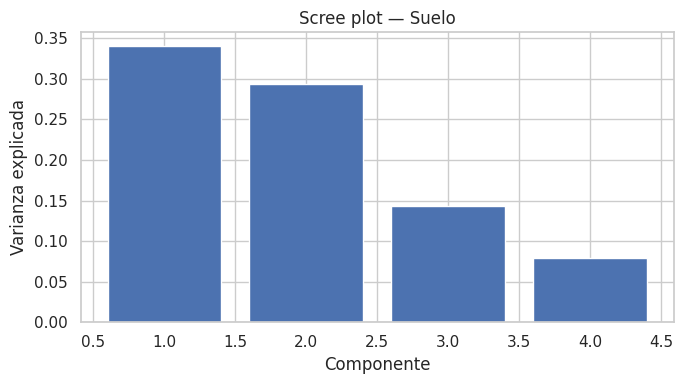

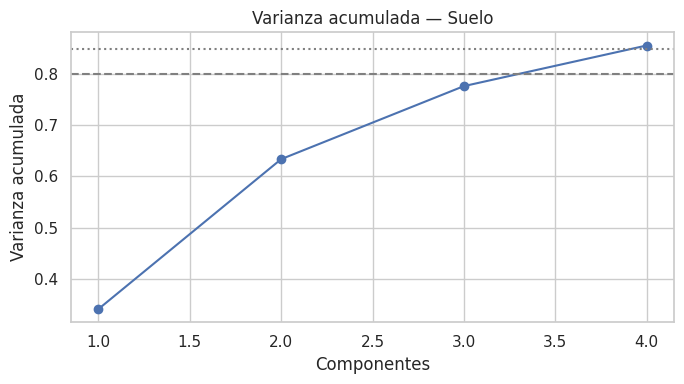

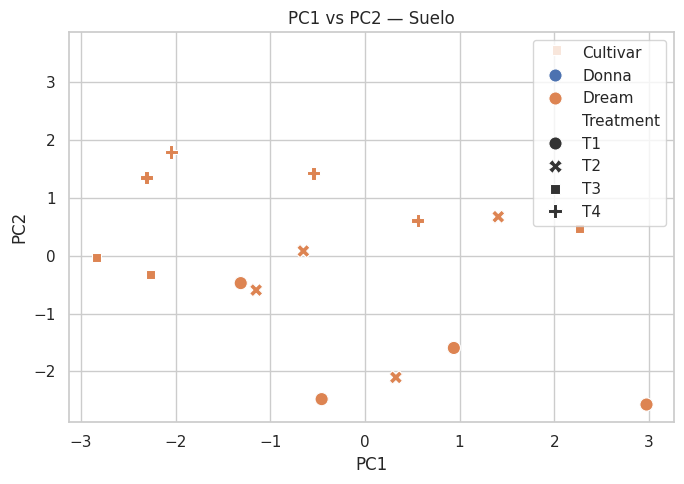

**Suelo — principales loadings de PC1**

,PC1
soil_N,0.468218
soil_N_mineral_incubado,-0.421423
soil_Densidad ap,-0.412885
soil_C org,0.384892
soil_C:N,-0.336034
soil_N _mineral _sinincubar,-0.328602
soil_N_microbiano_sinincubar,-0.241649
soil_Respiracion_microb (ug C-CO2/gsuelo·dia),-0.069977


**Suelo — principales loadings de PC2**

,PC2
soil_Microbial_biomass_C_sinincubar,0.517537
soil_Respiracion_microb (ug C-CO2/gsuelo·dia),-0.480417
soil_N_microbiano_sinincubar,0.424254
soil_Microbial_biomass_C_incubado,0.372943
soil_C org,-0.254045
soil_C:N,-0.249350
soil_Densidad ap,-0.203461
soil_N _mineral _sinincubar,-0.080622


**Suelo — principales loadings de PC3**

,PC3
soil_N _mineral _sinincubar,0.616021
soil_N_mineral_incubado,0.423327
soil_N,0.391174
soil_C:N,-0.352060
soil_Microbial_biomass_C_incubado,-0.262128
soil_C org,0.183090
soil_Microbial_biomass_C_sinincubar,0.159928
soil_Respiracion_microb (ug C-CO2/gsuelo·dia),0.153727


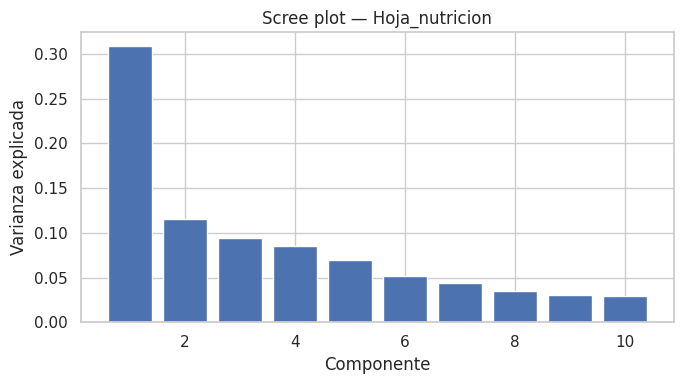

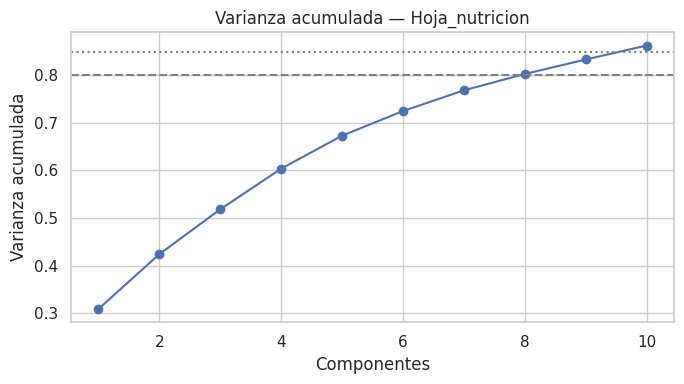

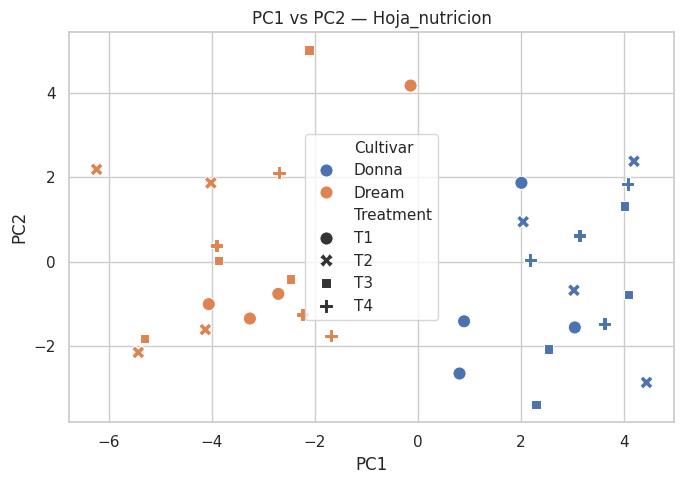

**Hoja_nutricion — principales loadings de PC1**

,PC1
leaf_nut_Mn_March,0.249347
leaf_nut_Mg_March,0.246894
leaf_nut_P_March,0.242649
leaf_nut_Co_March,-0.239371
FE_delta_leaf_nut_P,-0.229661
FE_delta_leaf_nut_Co,0.226524
FE_delta_leaf_iso_%N,-0.225830
FE_delta_leaf_nut_Ca,0.223445


**Hoja_nutricion — principales loadings de PC2**

,PC2
leaf_nut_Cr_March,0.348733
leaf_nut_Ni_March,0.326263
FE_delta_leaf_nut_Cr,-0.292467
FE_delta_leaf_nut_B,-0.277625
FE_delta_leaf_no3_mg NO3-/ 100 mg DW,-0.272701
FE_delta_leaf_nut_Mg,-0.244904
leaf_nut_Mo_March,0.240248
leaf_nut_B_March,0.234196


**Hoja_nutricion — principales loadings de PC3**

,PC3
leaf_nut_Cd_March,0.337548
FE_delta_leaf_nut_Cd,-0.272718
FE_delta_leaf_nut_Cr,0.245547
leaf_nut_Cu_March,0.244391
leaf_nut_Zn_March,0.242379
FE_delta_leaf_nut_Pb,-0.240976
leaf_nut_Pb_March,0.215111
FE_delta_leaf_nut_Ni,0.209513


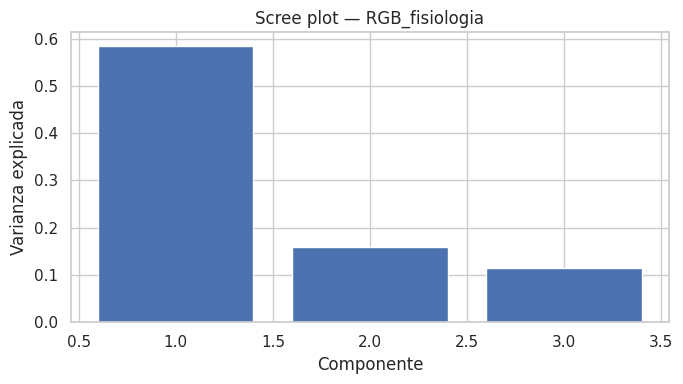

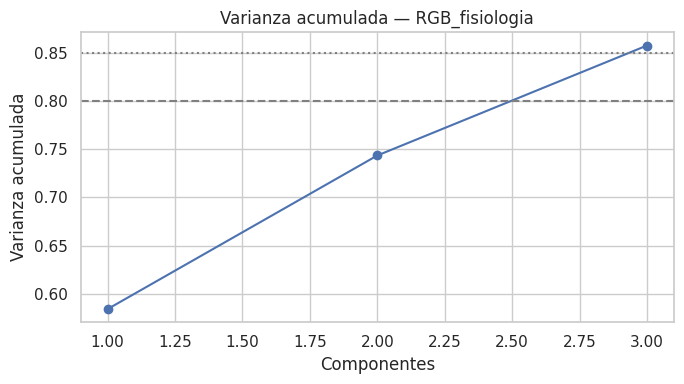

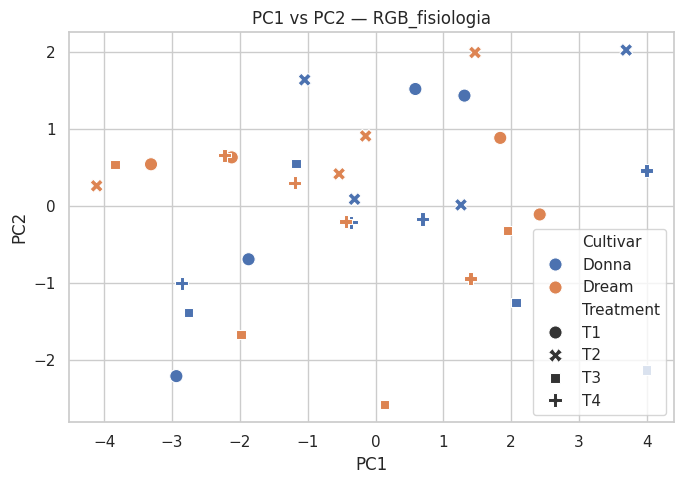

**RGB_fisiologia — principales loadings de PC1**

,PC1
FE_delta_leaf_rgb_GGA_March_minus_December,0.419189
FE_delta_leaf_rgb_GA_March_minus_December,0.395270
leaf_rgb_GGA_December,-0.393705
leaf_rgb_CSI_December,0.343550
leaf_rgb_GA_December,-0.337999
FE_delta_leaf_rgb_CSI_March_minus_December,-0.327145
FE_delta_leaf_rgb_GGA_May_minus_March,-0.296981
FE_delta_leaf_rgb_GA_May_minus_March,-0.224307


**RGB_fisiologia — principales loadings de PC2**

,PC2
FE_delta_leaf_rgb_GGA_May_minus_March,0.594139
FE_delta_leaf_rgb_GA_May_minus_March,0.433838
FE_delta_leaf_rgb_CSI_May_minus_March,-0.412113
leaf_rgb_CSI_December,0.340906
FE_delta_leaf_rgb_CSI_March_minus_December,-0.315040
leaf_rgb_GGA_December,-0.224313
leaf_rgb_GA_December,-0.120128
FE_delta_leaf_rgb_GGA_March_minus_December,0.066611


**RGB_fisiologia — principales loadings de PC3**

,PC3
FE_delta_leaf_rgb_CSI_May_minus_March,0.742167
FE_delta_leaf_rgb_GA_May_minus_March,0.610843
FE_delta_leaf_rgb_GA_March_minus_December,-0.166554
FE_delta_leaf_rgb_CSI_March_minus_December,-0.165077
leaf_rgb_CSI_December,0.093070
FE_delta_leaf_rgb_GGA_May_minus_March,-0.072681
leaf_rgb_GA_December,0.060915
FE_delta_leaf_rgb_GGA_March_minus_December,-0.058366


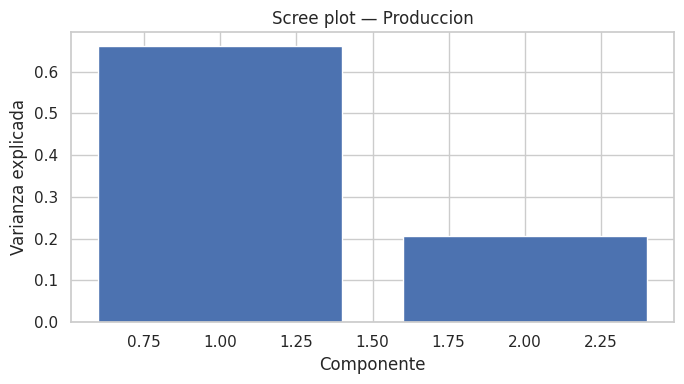

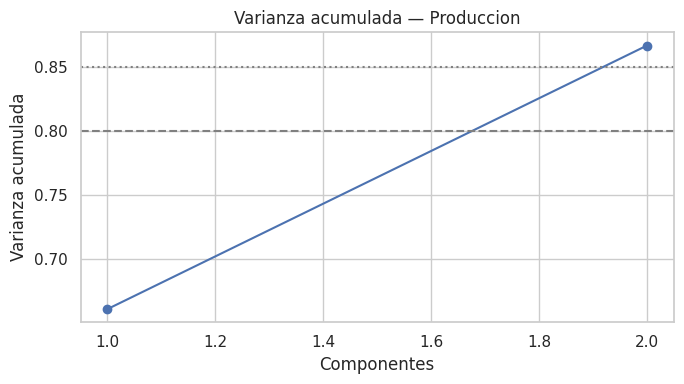

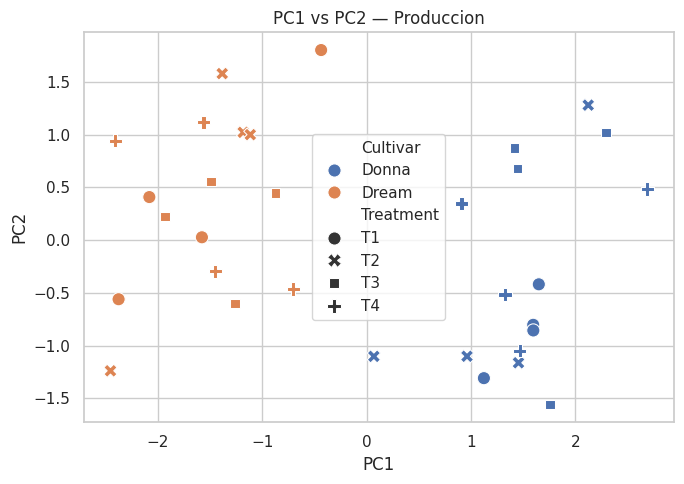

**Produccion — principales loadings de PC1**

,PC1
yield_Com Ton/ha,0.587362
yield_g/planta,0.572603
yield_Nº de plantes,0.472229
yield_No com Ton/ha,0.322694


**Produccion — principales loadings de PC2**

,PC2
yield_No com Ton/ha,0.919994
yield_g/planta,-0.286961
yield_Com Ton/ha,-0.262910
yield_Nº de plantes,0.046294


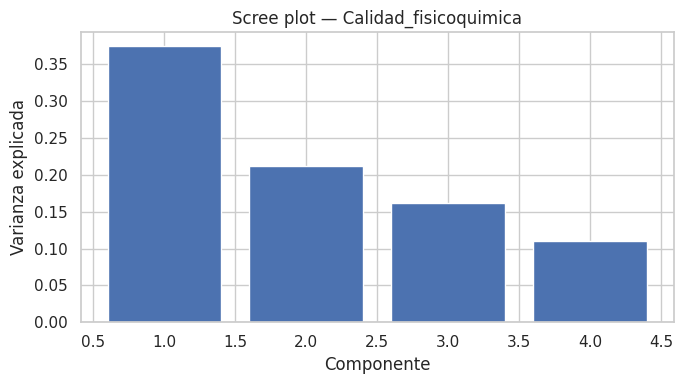

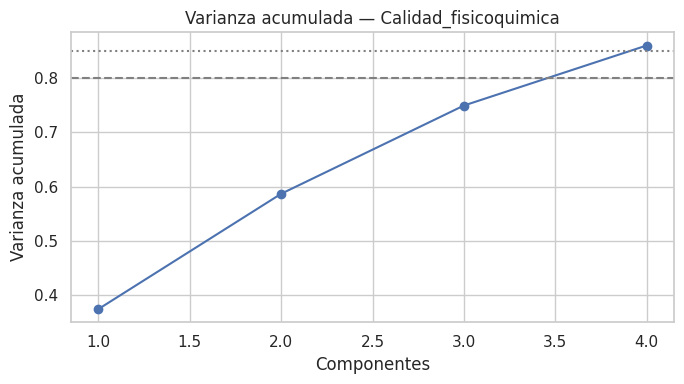

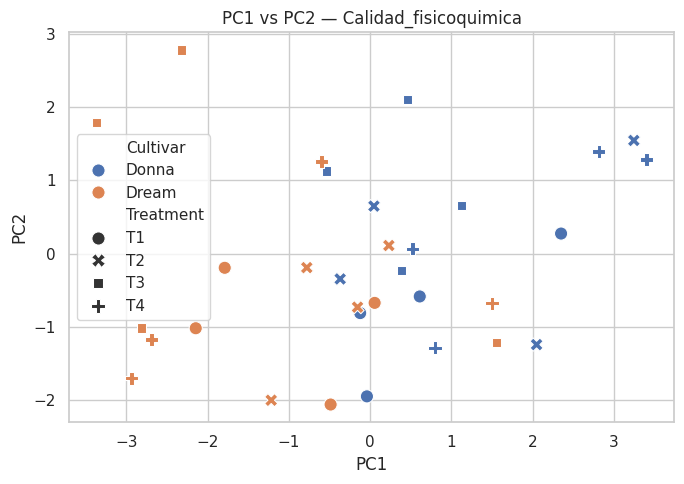

**Calidad_fisicoquimica — principales loadings de PC1**

,PC1
fruit_GGA,0.494783
fruit_GA,0.489478
fruit_BRIX,-0.432814
fruit_Firm,-0.379471
fruit_Hydrat,0.375104
fruit_CSI,-0.193558
fruit_Weight,-0.072211
fruit_Acidity,-0.029888


**Calidad_fisicoquimica — principales loadings de PC2**

,PC2
fruit_CSI,0.606165
fruit_Weight,-0.508167
fruit_Acidity,-0.431002
fruit_GA,0.279277
fruit_GGA,-0.278228
fruit_Hydrat,0.181963
fruit_BRIX,-0.005243
fruit_Firm,0.004771


**Calidad_fisicoquimica — principales loadings de PC3**

,PC3
fruit_Hydrat,0.518095
fruit_Acidity,0.497998
fruit_Weight,0.397911
fruit_CSI,0.381731
fruit_GGA,-0.265135
fruit_Firm,-0.264232
fruit_BRIX,0.185638
fruit_GA,0.070335


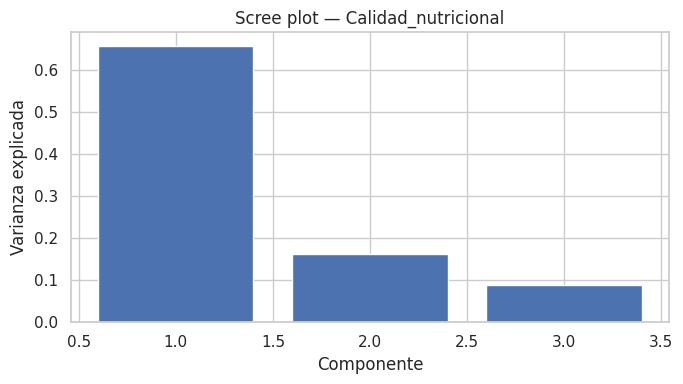

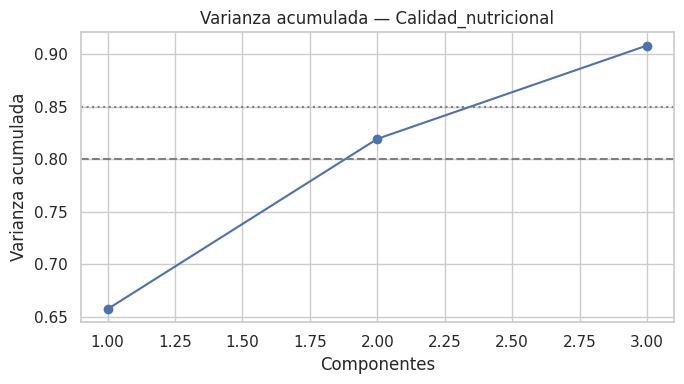

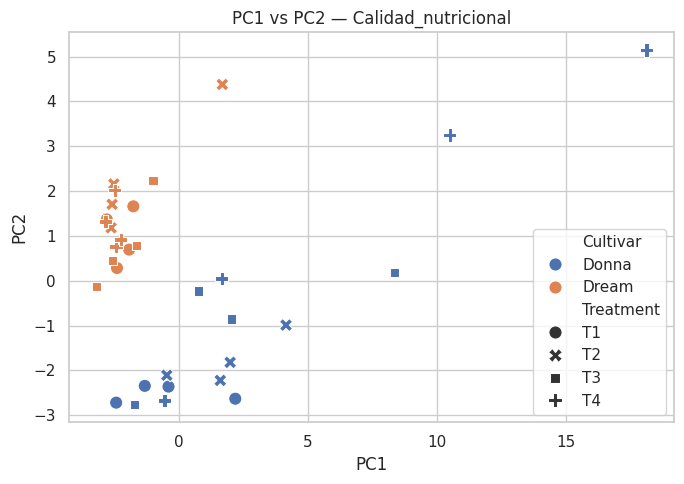

**Calidad_nutricional — principales loadings de PC1**

,PC1
Catechin,0.287649
Procyanidin B1,0.286510
Nar 7 gluc,0.283045
Phloridzin,0.280827
K-glucoside,0.279042
Procyanidin B3,0.278317
Epicatechin,0.275473
Gallic acid,0.253372


**Calidad_nutricional — principales loadings de PC2**

,PC2
Chlorogenic,0.438656
K-rutinoside,0.406145
Rutin,0.399423
Vit C,0.339770
Hydroxybenzoic 2,0.333284
Hydroxybenzoic,0.298339
Total polyphenols,0.277193
Procyanidin C1,-0.172396


**Calidad_nutricional — principales loadings de PC3**

,PC3
Hydroxybenzoic,0.467997
Total polyphenols,0.408212
Quercetin-glucoside,-0.355476
Quercetin,-0.324797
Procyanidin C1,-0.312195
Chlorogenic,-0.276271
Rutin,-0.273892
K-rutinoside,-0.194556


In [26]:
# Visualizaciones e interpretación de cada PCA por bloque.
meta=work[['Cultivar','Treatment','Cultivar_Treatment','Parcel_ID']]
for name,res in pca_results.items():
    scores=res['scores']; load=res['loadings']; p=res['pca']
    if scores.shape[1]<2:
        continue
    cum=np.cumsum(p.explained_variance_ratio_)

    fig,ax=plt.subplots(figsize=(7,4))
    ax.bar(range(1,len(p.explained_variance_ratio_)+1),p.explained_variance_ratio_)
    ax.set(xlabel='Componente',ylabel='Varianza explicada',title=f'Scree plot — {name}')
    plt.tight_layout(); plt.show()

    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(range(1,len(cum)+1),cum,marker='o')
    ax.axhline(.80,linestyle='--',color='gray'); ax.axhline(.85,linestyle=':',color='gray')
    ax.set(xlabel='Componentes',ylabel='Varianza acumulada',title=f'Varianza acumulada — {name}')
    plt.tight_layout(); plt.show()

    plot_df=meta.join(scores[['PC1','PC2']])
    fig,ax=plt.subplots(figsize=(7,5))
    sns.scatterplot(data=plot_df,x='PC1',y='PC2',hue='Cultivar',style='Treatment',s=90,ax=ax)
    ax.set_title(f'PC1 vs PC2 — {name}'); plt.tight_layout(); plt.show()

    for pc in [c for c in ['PC1','PC2','PC3'] if c in load.columns]:
        top=load[pc].abs().sort_values(ascending=False).head(8).index
        display(Markdown(f'**{name} — principales loadings de {pc}**'))
        display(load.loc[top,[pc]].sort_values(pc,key=lambda s:s.abs(),ascending=False))

,Componente,Varianza,Acumulada
0,PC1,0.224739,0.224739
1,PC2,0.112811,0.337550
2,PC3,0.106366,0.443917
3,PC4,0.082564,0.526480
4,PC5,0.069588,0.596068
5,PC6,0.066803,0.662872
6,PC7,0.050138,0.713010
7,PC8,0.043229,0.756239
8,PC9,0.034387,0.790626
9,PC10,0.032825,0.823451


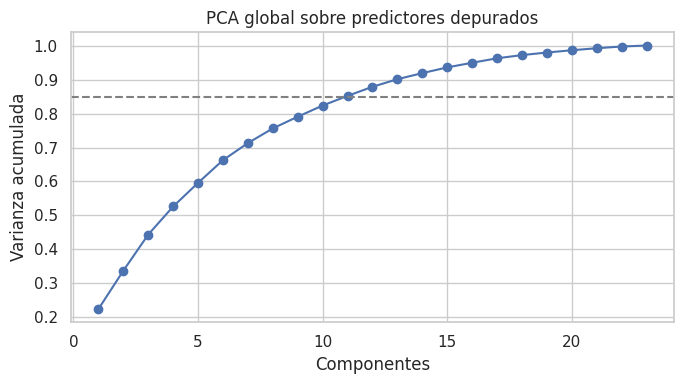

Variables iniciales X: 64 → depuradas: 60 → PCA 85%: 11 componentes (85.19%)


In [27]:
# 10.2 PCA global sobre X depurada.
pca_base=selected_corr
max_comp=min(len(pca_base),len(Xtr_num)-1)
if max_comp>=2:
    pca_full=PCA(n_components=max_comp,random_state=SEED).fit(Xtr_num[pca_base])
    cum=np.cumsum(pca_full.explained_variance_ratio_)
    n80=int(np.searchsorted(cum,.80)+1); n85=int(np.searchsorted(cum,.85)+1)
    n_comp=max(2,n85)
    pca_global=PCA(n_components=n_comp,random_state=SEED)
    score_tr=pca_global.fit_transform(Xtr_num[pca_base]); score_te=pca_global.transform(Xte_num[pca_base])
    pca_cols=[f'PC{i+1}' for i in range(n_comp)]
    pca_scores=pd.concat([
        pd.DataFrame(score_tr,index=tr.index,columns=pca_cols),
        pd.DataFrame(score_te,index=te.index,columns=pca_cols)
    ]).sort_index()
    pca_loadings=pd.DataFrame(pca_global.components_.T,index=pca_base,columns=pca_cols)
    var_report=pd.DataFrame({'Componente':pca_cols,'Varianza':pca_global.explained_variance_ratio_,'Acumulada':np.cumsum(pca_global.explained_variance_ratio_)})
    display(var_report)
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(range(1,len(cum)+1),cum,marker='o'); ax.axhline(.85,linestyle='--',color='gray')
    ax.set(xlabel='Componentes',ylabel='Varianza acumulada',title='PCA global sobre predictores depurados')
    plt.tight_layout(); plt.show()
    print(f'Variables iniciales X: {len(num_cols)} → depuradas: {len(selected_corr)} → PCA 85%: {n_comp} componentes ({100*var_report.Acumulada.iloc[-1]:.2f}%)')
else:
    raise ValueError('No existen suficientes dimensiones para PCA global.')

# 11. Exploración complementaria con Machine Learning

### ¿Qué haremos?
Aplicaremos K-Means y clustering jerárquico sobre la representación PCA global.

### ¿Por qué?
El clustering permite explorar si las observaciones forman perfiles naturales sin imponer previamente las categorías de tratamiento o cultivar.

### ¿Qué esperamos obtener?
Una señal exploratoria sobre agrupamientos internos y su relación posterior con `Treatment`, `Cultivar` y `Cultivar_Treatment`. Un cluster no se interpretará automáticamente como bueno o malo.

,k,Silhouette,Calinski_Harabasz
0,2,0.193758,8.585481
1,3,0.201243,7.214738
2,4,0.176302,6.020366
3,5,0.152826,5.156710
4,6,0.151207,4.797572


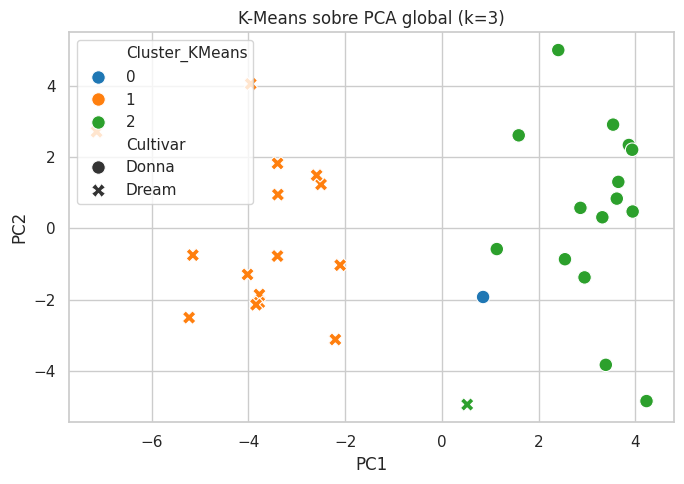

Cluster × Treatment


Treatment,T1,T2,T3,T4
Cluster_KMeans,,,,
0,1.00,0.00,0.00,0.00
1,0.20,0.27,0.27,0.27
2,0.25,0.25,0.25,0.25


Cluster × Cultivar


Cultivar,Donna,Dream
Cluster_KMeans,,
0,1.00,0.00
1,0.00,1.00
2,0.94,0.06


Cluster × Cultivar_Treatment


Cultivar_Treatment,Donna_T1,Donna_T2,Donna_T3,Donna_T4,Dream_T1,Dream_T2,Dream_T3,Dream_T4
Cluster_KMeans,,,,,,,,
0,1,0,0,0,0,0,0,0
1,0,0,0,0,3,4,4,4
2,3,4,4,4,1,0,0,0


In [28]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

cluster_input=pca_scores.copy()
# Usar como máximo los componentes necesarios para 85% ya calculados.
metrics=[]
for k in range(2,min(6,len(cluster_input)-1)+1):
    km=KMeans(n_clusters=k,random_state=SEED,n_init=20)
    labels=km.fit_predict(cluster_input)
    metrics.append({'k':k,'Silhouette':silhouette_score(cluster_input,labels),'Calinski_Harabasz':calinski_harabasz_score(cluster_input,labels)})
cluster_metrics=pd.DataFrame(metrics)
display(cluster_metrics)

best_k=int(cluster_metrics.sort_values(['Silhouette','Calinski_Harabasz'],ascending=False).iloc[0]['k'])
kmeans=KMeans(n_clusters=best_k,random_state=SEED,n_init=30)
k_labels=kmeans.fit_predict(cluster_input)
cluster_meta=work.loc[cluster_input.index,['Cultivar','Treatment','Cultivar_Treatment','Parcel_ID']].copy()
cluster_meta['Cluster_KMeans']=k_labels

plot_cluster=cluster_meta.join(cluster_input[['PC1','PC2']])
fig,ax=plt.subplots(figsize=(7,5))
sns.scatterplot(data=plot_cluster,x='PC1',y='PC2',hue='Cluster_KMeans',style='Cultivar',s=95,palette='tab10',ax=ax)
ax.set_title(f'K-Means sobre PCA global (k={best_k})'); plt.tight_layout(); plt.show()

print('Cluster × Treatment')
display(pd.crosstab(cluster_meta['Cluster_KMeans'],cluster_meta['Treatment'],normalize='index').round(2))
print('Cluster × Cultivar')
display(pd.crosstab(cluster_meta['Cluster_KMeans'],cluster_meta['Cultivar'],normalize='index').round(2))
print('Cluster × Cultivar_Treatment')
display(pd.crosstab(cluster_meta['Cluster_KMeans'],cluster_meta['Cultivar_Treatment']))

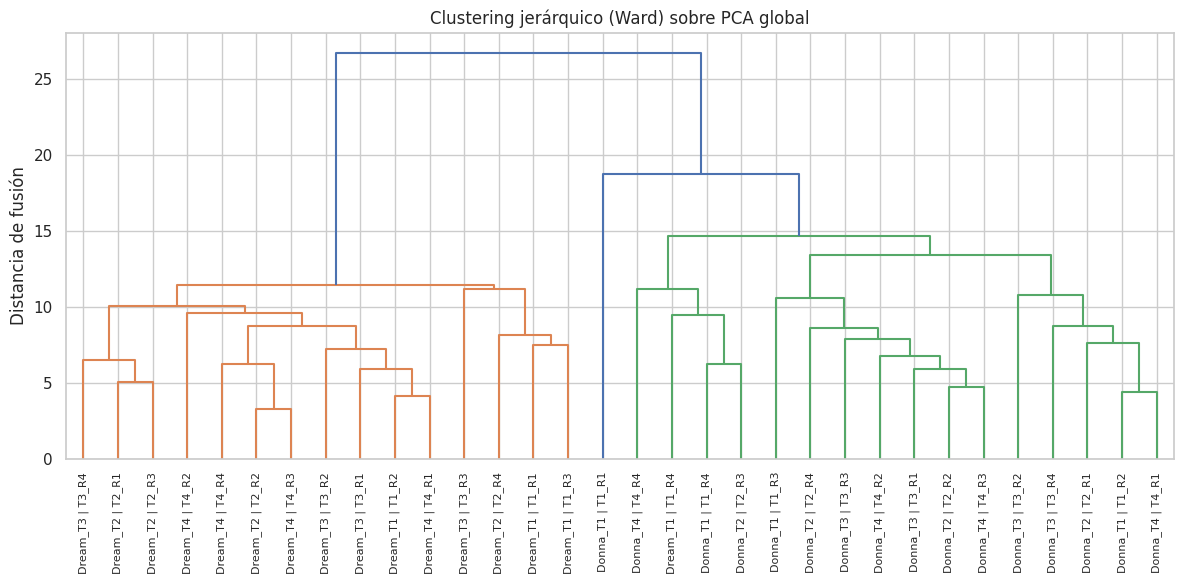

**Comparación exploratoria.** Para `k=3`, el acuerdo entre K-Means y clustering jerárquico medido con Adjusted Rand Index es **1.000**. El valor describe similitud entre particiones, no calidad biológica de los grupos.

In [29]:
# Clustering jerárquico y comparación cualitativa con K-Means.
Z=linkage(cluster_input.to_numpy(),method='ward')
labels_txt=(work.loc[cluster_input.index,'Cultivar_Treatment'].astype(str)+' | '+work.loc[cluster_input.index,'Parcel_ID'].astype(str)).tolist()
fig,ax=plt.subplots(figsize=(12,6))
dendrogram(Z,labels=labels_txt,leaf_rotation=90,ax=ax)
ax.set_title('Clustering jerárquico (Ward) sobre PCA global')
ax.set_ylabel('Distancia de fusión')
plt.tight_layout(); plt.show()

agg=AgglomerativeClustering(n_clusters=best_k,linkage='ward')
h_labels=agg.fit_predict(cluster_input)
cluster_meta['Cluster_Hierarchical']=h_labels
ari=adjusted_rand_score(k_labels,h_labels)
display(Markdown(f'**Comparación exploratoria.** Para `k={best_k}`, el acuerdo entre K-Means y clustering jerárquico medido con Adjusted Rand Index es **{ari:.3f}**. El valor describe similitud entre particiones, no calidad biológica de los grupos.'))

# 12. Dataset preparado y trazabilidad

### ¿Qué haremos?
Exportaremos los principales productos de esta fase y una bitácora de variables descartadas.

### ¿Por qué?
La preparación de datos debe ser reproducible y permitir rastrear qué ocurrió con cada variable.

### ¿Qué esperamos obtener?
Archivos reutilizables para etapas posteriores de modelado, sin perder identificadores experimentales.

In [30]:
# Bitácora completa de variables retiradas.
removed_records=[]
for c in temporal_removed:
    removed_records.append({'Feature':c,'Etapa':'Redundancia temporal','Razón':'Reemplazada por baseline + delta'})
for c in all_missing:
    removed_records.append({'Feature':c,'Etapa':'Missingness','Razón':'Completamente ausente en train'})
removed_records.extend(filter_log)
features_removed=pd.DataFrame(removed_records).drop_duplicates()

# Combinar matrices de train y test respetando el índice original.
Xall_filtered=pd.concat([Xtr_depurado,Xte_depurado]).sort_index()
X_pca_global=pd.concat([work.loc[pca_scores.index,['Cultivar','Treatment','Replicate','Parcel_ID']].reset_index(drop=True),
                        pca_scores.reset_index(drop=True)],axis=1)

ana_fe.to_csv(OUT/'dataset_feature_engineered.csv',index=False)
X_filtered_export=pd.concat([work.loc[Xall_filtered.index,['Cultivar','Treatment','Replicate','Parcel_ID']].reset_index(drop=True),
                             Xall_filtered.reset_index(drop=True)],axis=1)
X_filtered_export.to_csv(OUT/'X_filtered.csv',index=False)
X_pca_global.to_csv(OUT/'X_pca_global.csv',index=False)
outlier_registry.to_csv(OUT/'outlier_registry.csv',index=False)
features_removed.to_csv(OUT/'features_removed.csv',index=False)

if not family_relevance.empty:
    family_relevance.to_csv(OUT/'relevancia_por_familias.csv')
cluster_metrics.to_csv(OUT/'clustering_metrics.csv',index=False)
cluster_meta.to_csv(OUT/'clustering_assignments.csv',index=False)
transform_report.to_csv(OUT/'auditoria_transformaciones.csv',index=False)

print('Archivos exportados a:',OUT)
print('\nProductos principales:')
for f in ['dataset_feature_engineered.csv','X_filtered.csv','X_pca_global.csv','outlier_registry.csv','features_removed.csv']:
    print(' -',f)

Archivos exportados a: /mnt/data/outputs/feature_engineering

Productos principales:
 - dataset_feature_engineered.csv
 - X_filtered.csv
 - X_pca_global.csv
 - outlier_registry.csv
 - features_removed.csv


# 13. Conclusiones — Preparación de datos / CRISP-ML(Q)

Las conclusiones de esta fase se generan a partir de los resultados realmente obtenidos durante la ejecución de la libreta.

# Conclusiones dinámicas basadas en los resultados reales.

### Conclusiones generales

1. Se preservó la estructura experimental con **{len(work)} observaciones** y **{work.Parcel_ID.nunique()} parcelas**, manteniendo `Cultivar`, `Treatment`, `Replicate` y `Parcel_ID` para trazabilidad.

2. La separación train/test se realizó por parcela y se verificó que no existe solapamiento entre grupos, reduciendo el riesgo de *data leakage*.

3. La auditoría detectó **{len(outlier_registry)} casos variable-observación atípicos** mediante IQR. Ninguno fue eliminado automáticamente; los extremos se conservan como señales para investigación hasta confirmar si corresponden a errores o a respuestas biológicas reales.

4. Se definió una política explícita de limpieza y preprocesamiento antes de modificar los datos.

5. Se generaron **{len(derived)} características temporales** y se retiraron **{len(temporal_removed)} mediciones finales redundantes**, representando la evolución mediante baseline + delta.

6. Yeo-Johnson se aplicó a **{len(transformers)} variables** con `|skew| > 1`, y StandardScaler permitió comparar variables medidas en unidades heterogéneas.

7. Los filtros de varianza, duplicación y Spearman redujeron los predictores numéricos de **{len(num_cols)}** a **{len(selected_corr)}** sin utilizar un único outcome como criterio de exclusión.

8. La relevancia supervisada se evaluó por familias de **producción, calidad fisicoquímica y calidad nutricional**, evitando tratar `yield_g/planta` como único resultado científico.

9. PCA se aplicó por bloques y globalmente. El PCA global representa los predictores depurados mediante **{n_comp} componentes** para alcanzar aproximadamente **{100*var_report.Acumulada.iloc[-1]:.1f}%** de varianza explicada acumulada.

10. K-Means y clustering jerárquico se utilizaron de forma exploratoria sobre la representación PCA para identificar perfiles internos sin imponer previamente categorías de tratamiento o cultivar.

### Relación con CRISP-ML(Q)

Estas actividades corresponden a la fase de **Data Preparation** de CRISP-ML(Q): integración, limpieza, transformación, construcción, selección y reducción de características. El resultado no es todavía un modelo final, sino una base analítica documentada y reproducible para las siguientes etapas de modelado y evaluación.
"""
display(Markdown(conclusions))